In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import gaussian
from skimage.morphology import skeletonize, remove_small_objects, closing, disk
from skimage.feature import hessian_matrix
from skimage import measure
from skimage.filters import frangi
from scipy.ndimage import convolve, label
from scipy.spatial import cKDTree



def prune_skeleton_spurs_smart(skeleton, heatmap, min_branch_length=60, max_iter=3):
    """
    智能骨架毛刺修剪：加入边界保护与热力值加权，防止误删源头主干
    :param skeleton: 二值骨架图
    :param heatmap: 对数压缩后的热力图底图 (用于评估支流热力高低)
    :param min_branch_length: 允许保留的末端分支最小长度 (调小至60，保护左上角短主干)
    """
    pruned = skeleton.copy().astype(bool)
    h, w = skeleton.shape
    
    # 8连通邻域卷积核，用于计算当前像素周边的邻居数量
    kernel = np.array([[1, 1, 1],
                       [1, 0, 1],
                       [1, 1, 1]])
                       
    for iteration in range(max_iter):
        # 1. 计算每个骨架像素的邻居数
        neighbors = convolve(pruned.astype(np.uint8), kernel, mode='constant')
        
        # 2. 识别端点 (邻居为1) 和 交叉点 (邻居>2)
        endpoints = pruned & (neighbors == 1)
        intersections = pruned & (neighbors > 2)
        
        # 如果当前骨架已经没有任何端点 (纯环状)，直接结束
        if not np.any(endpoints):
            break
        
        # 3. 抠除交叉点，打断骨架，形成独立的线段
        segments = pruned & ~intersections
        
        # 4. 对独立线段进行连通域标记
        labeled_segments, num_features = label(segments, structure=np.ones((3,3)))
        
        branches_removed = False
        
        # 5. 查找并删除过短的末端分支
        for i in range(1, num_features + 1):
            mask = (labeled_segments == i)
            
            # 核心判断 1：该线段是否包含端点 (是否为末端分支)
            is_endpoint_branch = np.any(mask & endpoints)
            
            if is_endpoint_branch:
                # 核心判断 2【边界保护】：如果这个分支触碰了图像边缘（四周各留5个像素的安全区），绝对不删！
                # 这样能保证河流源头（左上角边缘）和出口完美延伸到最外围。
                touches_boundary = np.any(mask[0:5, :]) or np.any(mask[h-5:h, :]) or \
                                   np.any(mask[:, 0:5]) or np.any(mask[:, w-5:w])
                
                if touches_boundary:
                    continue # 触碰边界的末端分支直接放过，保留！
                
                # 核心判断 3【热力加权】：计算该分支上的平均热力值
                # 如果虽然短，但热力值极高（说明是高热力支流），也可以选择保留
                branch_mean_heat = np.mean(heatmap[mask])
                
                # 综合判断：长度小于阈值 且 热力没有特别突出的，才判定为毛刺删除
                length = np.sum(mask)
                if length < min_branch_length:
                    pruned[mask] = False
                    branches_removed = True
                    
        if not branches_removed:
            break
            
        pruned = skeletonize(pruned)
        
    return pruned


def _build_skeleton_graph(skeleton):
    """
    将二值骨架图构建为8连通图，返回图节点、邻接表、度数信息
    """
    h, w = skeleton.shape
    ys, xs = np.where(skeleton)
    node_set = set(zip(ys.tolist(), xs.tolist()))
    adj = {n: [] for n in node_set}
    for y, x in node_set:
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx = y + dy, x + dx
                if (ny, nx) in node_set:
                    adj[(y, x)].append((ny, nx))
    degree = {n: len(neighbors) for n, neighbors in adj.items()}
    return node_set, adj, degree


def _trace_branch_from_endpoint(skeleton, start, adj, max_length=10000):
    """
    从端点或交汇点邻域出发，沿骨架追踪一条分支直到下一个端点/交汇点
    返回路径点列表 [(y,x), ...]
    """
    path = [start]
    visited = {start}
    current = start
    neighbors = adj.get(current, [])
    if len(neighbors) == 0:
        return path
    prev = None
    while True:
        next_candidates = [n for n in adj.get(current, []) if n not in visited]
        if len(next_candidates) == 0:
            break
        if len(next_candidates) == 1:
            nxt = next_candidates[0]
        else:
            if prev is None:
                nxt = next_candidates[0]
            else:
                dy_prev = current[0] - prev[0]
                dx_prev = current[1] - prev[1]
                best_score = -999
                nxt = next_candidates[0]
                for cand in next_candidates:
                    dy_c = cand[0] - current[0]
                    dx_c = cand[1] - current[1]
                    score = dy_prev * dy_c + dx_prev * dx_c
                    if score > best_score:
                        best_score = score
                        nxt = cand
        path.append(nxt)
        visited.add(nxt)
        prev = current
        current = nxt
        if len(path) >= max_length:
            break
    return path


def _compute_hessian_fields(heatmap, sigma=5.0):
    """
    计算Hessian矩阵场，提取每个像素的脊线强度、切线方向、法线方向
    :param heatmap: 连续数值热力图（建议用log压缩+平滑后的）
    :param sigma: Hessian计算的尺度参数，应与河流宽度匹配
    :return: ridge_strength (H,W), tangent_field (H,W,2), normal_field (H,W,2)
    """
    smoothed = gaussian(heatmap.astype(np.float64), sigma=sigma)
    Hrr, Hrc, Hcc = hessian_matrix(smoothed, sigma=sigma, order='rc')
    H, W = heatmap.shape
    ridge_strength = np.zeros((H, W), dtype=np.float64)
    tangent_field = np.zeros((H, W, 2), dtype=np.float64)
    normal_field = np.zeros((H, W, 2), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            H_mat = np.array([[Hrr[y, x], Hrc[y, x]],
                               [Hrc[y, x], Hcc[y, x]]])
            eigenvalues, eigenvectors = np.linalg.eigh(H_mat)
            idx = np.argsort(np.abs(eigenvalues))[::-1]
            eigenvalues = eigenvalues[idx]
            eigenvectors = eigenvectors[:, idx]
            if eigenvalues[0] < 0:
                ridge_strength[y, x] = -eigenvalues[0]
                normal_field[y, x] = eigenvectors[:, 0]
                tangent_field[y, x] = eigenvectors[:, 1]
    return ridge_strength, tangent_field, normal_field


def _trace_ridge_hessian(start_y, start_x, direction, ridge_strength,
                          tangent_field, heatmap_smoothed,
                          max_steps=80, step_size=1.0,
                          ridge_min_strength=0.01):
    """
    从断口端点出发，沿Hessian切线方向追踪脊线
    在交汇区域，切线方向自然跟随各自支流，不会提前合并
    :param start_y, start_x: 断口端点坐标
    :param direction: 初始追踪方向 (2,)，应指向交汇区域内部
    :param ridge_strength, tangent_field: Hessian场
    :param heatmap_smoothed: 平滑热力图（用于梯度微调）
    :param max_steps: 最大追踪步数
    :param step_size: 每步步长（像素）
    :return: path [(y,x), ...]
    """
    H, W = ridge_strength.shape
    path = [(int(start_y), int(start_x))]
    cy, cx = float(start_y), float(start_x)
    cur_dir = direction.copy()
    cur_dir_norm = np.linalg.norm(cur_dir)
    if cur_dir_norm < 1e-8:
        return path
    cur_dir /= cur_dir_norm
    gy_field, gx_field = np.gradient(heatmap_smoothed)
    for _ in range(max_steps):
        iy, ix = int(round(cy)), int(round(cx))
        if not (0 <= iy < H and 0 <= ix < W):
            break
        if ridge_strength[iy, ix] < ridge_min_strength:
            break
        local_tangent = tangent_field[iy, ix]
        tangent_norm = np.linalg.norm(local_tangent)
        if tangent_norm < 1e-8:
            break
        local_tangent /= tangent_norm
        if np.dot(local_tangent, cur_dir) < 0:
            local_tangent = -local_tangent
        cur_dir = 0.6 * cur_dir + 0.4 * local_tangent
        cur_dir /= np.linalg.norm(cur_dir)
        next_y = cy + cur_dir[0] * step_size
        next_x = cx + cur_dir[1] * step_size
        perp = np.array([-cur_dir[1], cur_dir[0]])
        best_offset = 0.0
        best_heat = -1.0
        for offset in np.linspace(-3, 3, 7):
            py = int(round(next_y + perp[0] * offset))
            px = int(round(next_x + perp[1] * offset))
            if 0 <= py < H and 0 <= px < W:
                h = heatmap_smoothed[py, px]
                if h > best_heat:
                    best_heat = h
                    best_offset = offset
        next_y += perp[0] * best_offset
        next_x += perp[1] * best_offset
        niy, nix = int(round(next_y)), int(round(next_x))
        if not (0 <= niy < H and 0 <= nix < W):
            break
        path.append((niy, nix))
        cy, cx = next_y, next_x
    return path


def _find_closest_point_between_paths(path_a, path_b):
    """
    找两条路径之间距离最近的点对，返回 (point_a, point_b, distance)
    """
    if len(path_a) == 0 or len(path_b) == 0:
        return None, None, np.inf
    pts_a = np.array(path_a)
    pts_b = np.array(path_b)
    tree_b = cKDTree(pts_b)
    dists, indices = tree_b.query(pts_a)
    best_idx_a = np.argmin(dists)
    best_dist = dists[best_idx_a]
    best_idx_b = indices[best_idx_a]
    return tuple(pts_a[best_idx_a]), tuple(pts_b[best_idx_b]), best_dist


def _find_closest_point_on_path_to_target(path, target):
    """
    找路径上距离目标点最近的点及其索引
    :param path: [(y,x), ...]
    :param target: (y, x)
    :return: (closest_point, index_on_path, distance)
    """
    if len(path) == 0:
        return None, -1, np.inf
    pts = np.array(path)
    tgt = np.array(target)
    dists = np.sqrt(np.sum((pts - tgt) ** 2, axis=1))
    best_idx = np.argmin(dists)
    return tuple(pts[best_idx]), int(best_idx), dists[best_idx]


def _trim_ridge_to_junction(traced_ridge, true_junction, trim_margin=3):
    """
    将追踪脊线修剪到距真实交汇点最近的位置
    丢弃超过交汇点之后的部分（避免脊线越过交汇点延伸到另一支流）
    :param traced_ridge: 追踪脊线 [(y,x), ...]
    :param true_junction: 真实交汇点 (y, x)
    :param trim_margin: 在最近点之后再保留几个点（用于桥接时估计切线方向）
    :return: trimmed_ridge [(y,x), ...], endpoint_tangent (2,)
    """
    closest_pt, closest_idx, closest_dist = _find_closest_point_on_path_to_target(
        traced_ridge, true_junction
    )
    if closest_idx < 0:
        return traced_ridge, np.array([0.0, 1.0])
    trim_end = min(closest_idx + trim_margin + 1, len(traced_ridge))
    trimmed = traced_ridge[:trim_end]
    tangent_len = min(5, len(trimmed))
    if tangent_len >= 2:
        p_end = np.array(trimmed[-1], dtype=np.float64)
        p_prev = np.array(trimmed[-tangent_len], dtype=np.float64)
        tangent = p_end - p_prev
        t_norm = np.linalg.norm(tangent)
        if t_norm > 1e-8:
            tangent /= t_norm
        else:
            tangent = np.array([0.0, 1.0])
    else:
        tangent = np.array([0.0, 1.0])
    return trimmed, tangent


def _trace_ridge_to_target(start_y, start_x, start_tangent,
                            target_y, target_x,
                            ridge_strength, tangent_field, heatmap_smoothed,
                            max_steps=120, step_size=1.0,
                            ridge_min_strength=0.01,
                            attraction_strength=0.3):
    """
    目标引导的Hessian脊线追踪：从断口端点追踪到目标点（真实交汇点）
    方向 = (1-w)*Hessian切线 + w*目标引力，w随距离递增
    越靠近目标，目标引力越强，自然形成顺滑过渡
    :param start_y, start_x: 起点坐标
    :param start_tangent: 起点切线方向 (2,)，确保方向连续
    :param target_y, target_x: 目标点坐标（真实交汇点）
    :param ridge_strength, tangent_field: Hessian场
    :param heatmap_smoothed: 平滑热力图
    :param max_steps: 最大步数
    :param step_size: 步长
    :param ridge_min_strength: 脊线强度阈值
    :param attraction_strength: 目标引力基础强度（0~1）
    :return: path [(y,x), ...]
    """
    H, W = ridge_strength.shape
    path = [(int(start_y), int(start_x))]
    cy, cx = float(start_y), float(start_x)
    cur_dir = start_tangent.copy()
    cur_dir_n = np.linalg.norm(cur_dir)
    if cur_dir_n < 1e-8:
        return path
    cur_dir /= cur_dir_n
    total_dist = np.sqrt((start_y - target_y)**2 + (start_x - target_x)**2)
    if total_dist < 1.0:
        return path
    arrive_dist = step_size * 1.5
    for step in range(max_steps):
        dy_to_tgt = target_y - cy
        dx_to_tgt = target_x - cx
        dist_to_tgt = np.sqrt(dy_to_tgt**2 + dx_to_tgt**2)
        if dist_to_tgt < arrive_dist:
            path.append((int(round(target_y)), int(round(target_x))))
            break
        iy, ix = int(round(cy)), int(round(cx))
        if not (0 <= iy < H and 0 <= ix < W):
            break
        dir_to_target = np.array([dy_to_tgt, dx_to_tgt], dtype=np.float64)
        dir_to_target /= dist_to_tgt
        hessian_weight = max(0.0, 1.0 - attraction_strength * (1.0 - dist_to_tgt / total_dist))
        target_weight = 1.0 - hessian_weight
        hessian_dir = cur_dir.copy()
        if 0 <= iy < H and 0 <= ix < W and ridge_strength[iy, ix] > ridge_min_strength:
            local_tangent = tangent_field[iy, ix]
            t_norm = np.linalg.norm(local_tangent)
            if t_norm > 1e-8:
                local_tangent /= t_norm
                if np.dot(local_tangent, cur_dir) < 0:
                    local_tangent = -local_tangent
                hessian_dir = 0.5 * cur_dir + 0.5 * local_tangent
                hessian_dir /= np.linalg.norm(hessian_dir)
        blended_dir = hessian_weight * hessian_dir + target_weight * dir_to_target
        b_norm = np.linalg.norm(blended_dir)
        if b_norm < 1e-8:
            blended_dir = dir_to_target
        else:
            blended_dir /= b_norm
        next_y = cy + blended_dir[0] * step_size
        next_x = cx + blended_dir[1] * step_size
        perp = np.array([-blended_dir[1], blended_dir[0]])
        best_offset = 0.0
        best_heat = -1.0
        for offset in np.linspace(-3, 3, 7):
            py = int(round(next_y + perp[0] * offset))
            px = int(round(next_x + perp[1] * offset))
            if 0 <= py < H and 0 <= px < W:
                ht = heatmap_smoothed[py, px]
                if ht > best_heat:
                    best_heat = ht
                    best_offset = offset
        next_y += perp[0] * best_offset
        next_x += perp[1] * best_offset
        niy, nix = int(round(next_y)), int(round(next_x))
        if not (0 <= niy < H and 0 <= nix < W):
            break
        path.append((niy, nix))
        cy, cx = next_y, next_x
        cur_dir = blended_dir.copy()
    return path


def _generate_smooth_bridge(ridge_endpoint_y, ridge_endpoint_x,
                             ridge_tangent,
                             junction_y, junction_x,
                             ridge_strength, tangent_field, heatmap_smoothed,
                             step_size=1.0, ridge_min_strength=0.01):
    """
    从脊线断口端点到真实交汇点生成顺滑桥接曲线
    使用目标引导的Hessian追踪，确保桥接曲线既沿热力脊线走，又顺滑到达交汇点
    :param ridge_endpoint_y, ridge_endpoint_x: 脊线断口端点
    :param ridge_tangent: 断口端点处的切线方向 (2,)
    :param junction_y, junction_x: 真实交汇点
    :param ridge_strength, tangent_field, heatmap_smoothed: Hessian场与热力图
    :return: bridge_path [(y,x), ...]
    """
    dist = np.sqrt((ridge_endpoint_y - junction_y)**2 +
                   (ridge_endpoint_x - junction_x)**2)
    if dist < 1.5:
        return [(int(round(junction_y)), int(round(junction_x)))]
    max_steps = int(dist / step_size) + 20
    attraction = 0.3 + 0.4 * min(1.0, 10.0 / max(dist, 1.0))
    bridge = _trace_ridge_to_target(
        ridge_endpoint_y, ridge_endpoint_x, ridge_tangent,
        junction_y, junction_x,
        ridge_strength, tangent_field, heatmap_smoothed,
        max_steps=max_steps, step_size=step_size,
        ridge_min_strength=ridge_min_strength,
        attraction_strength=attraction
    )
    return bridge


def fix_junctions_by_hessian_tracing(skeleton, heatmap_log, smoothed,
                                      sigma_hessian=7.0, junction_radius=40,
                                      ridge_min_strength_ratio=0.15,
                                      max_trace_steps=80):
    """
    方案3核心：基于Hessian脊线追踪修复交汇区域骨架
    在已有骨架上检测degree>=3的交汇节点，切除交汇区域骨架，
    利用Hessian切线场从各分支断口独立追踪脊线，
    追踪出的各支流脊线自然延伸相交，交点即为真实交汇点。
    :param skeleton: 原始二值骨架图（prune之后的）
    :param heatmap_log: log压缩后的热力图
    :param smoothed: 高斯平滑后的热力图
    :param sigma_hessian: Hessian尺度参数，应与河流半宽匹配
    :param junction_radius: 交汇区域切除半径（像素），
           建议取河流宽度的1.5~2倍
    :param ridge_min_strength_ratio: 脊线强度最低阈值（占最大值的比例）
    :param max_trace_steps: 从每个断口最大追踪步数
    :return: fixed_skeleton (修复后的二值骨架图),
             junction_info (交汇信息列表)
    """
    print("5. 正在基于Hessian脊线追踪修复交汇区域...")
    h, w = skeleton.shape
    node_set, adj, degree = _build_skeleton_graph(skeleton)
    junctions = [n for n, d in degree.items() if d >= 3]
    if len(junctions) == 0:
        print("   未检测到交汇节点，无需修复。")
        y_coords, x_coords = np.where(skeleton)
        coords = np.column_stack((x_coords, y_coords))
        return skeleton, coords, []
    print(f"   检测到 {len(junctions)} 个交汇节点: {junctions}")
    print(f"   计算Hessian场 (sigma={sigma_hessian})...")
    ridge_strength, tangent_field, normal_field = _compute_hessian_fields(
        smoothed, sigma=sigma_hessian
    )
    ridge_threshold = ridge_min_strength_ratio * np.max(ridge_strength)
    fixed_skeleton = skeleton.copy()
    junction_info = []
    for j_idx, (jy, jx) in enumerate(junctions):
        print(f"   处理交汇节点 {j_idx+1}/{len(junctions)}: ({jy}, {jx})")
        yy, xx = np.ogrid[:h, :w]
        dist_map = np.sqrt((yy - jy)**2 + (xx - jx)**2)
        excise_mask = dist_map <= junction_radius
        ring_inner = dist_map <= junction_radius * 0.7
        ring_outer = (dist_map > junction_radius * 0.7) & (dist_map <= junction_radius * 1.3)
        boundary_skel_y, boundary_skel_x = np.where(
            fixed_skeleton & ring_outer
        )
        if len(boundary_skel_y) < 2:
            print(f"     交汇区域边界骨架点不足，跳过。")
            continue
        fixed_skeleton[excise_mask & fixed_skeleton] = False
        branch_endpoints = list(zip(boundary_skel_y.tolist(),
                                    boundary_skel_x.tolist()))
        visited = set()
        branch_groups = []
        for ep in branch_endpoints:
            if ep in visited:
                continue
            group = [ep]
            visited.add(ep)
            for other in branch_endpoints:
                if other in visited:
                    continue
                if np.sqrt((ep[0]-other[0])**2 + (ep[1]-other[1])**2) < junction_radius * 0.5:
                    group.append(other)
                    visited.add(other)
            branch_groups.append(group)
        print(f"     识别到 {len(branch_groups)} 个分支断口组")
        if len(branch_groups) < 2:
            fixed_skeleton[excise_mask] = skeleton[excise_mask]
            continue
        traced_ridges = []
        for bg_idx, group in enumerate(branch_groups):
            rep = group[0]
            ey, ex = rep
            direction_to_junction = np.array([jy - ey, jx - ex], dtype=np.float64)
            dir_norm = np.linalg.norm(direction_to_junction)
            if dir_norm < 1e-8:
                continue
            direction_to_junction /= dir_norm
            local_tangent = tangent_field[ey, ex]
            if np.linalg.norm(local_tangent) > 1e-8:
                local_tangent = local_tangent / np.linalg.norm(local_tangent)
                if np.dot(local_tangent, direction_to_junction) < 0:
                    local_tangent = -local_tangent
                init_dir = 0.5 * direction_to_junction + 0.5 * local_tangent
            else:
                init_dir = direction_to_junction
            init_dir /= np.linalg.norm(init_dir)
            path = _trace_ridge_hessian(
                ey, ex, init_dir, ridge_strength, tangent_field,
                smoothed, max_steps=max_trace_steps, step_size=1.0,
                ridge_min_strength=ridge_threshold
            )
            traced_ridges.append(path)
            print(f"       分支 {bg_idx+1}: 从({ey},{ex})追踪到 {len(path)} 个点")
        if len(traced_ridges) < 2:
            fixed_skeleton[excise_mask] = skeleton[excise_mask]
            continue
        true_junction = None
        min_junc_dist = np.inf
        for i in range(len(traced_ridges)):
            for j in range(i + 1, len(traced_ridges)):
                pa, pb, dist = _find_closest_point_between_paths(
                    traced_ridges[i], traced_ridges[j]
                )
                if pa is not None and dist < min_junc_dist:
                    min_junc_dist = dist
                    ha = smoothed[pa[0], pa[1]]
                    hb = smoothed[pb[0], pb[1]]
                    true_junction = pa if ha >= hb else pb
        if true_junction is None:
            for path in traced_ridges:
                for py, px in path:
                    if 0 <= py < h and 0 <= px < w:
                        fixed_skeleton[py, px] = True
            junction_info.append({
                'original_junction': (jy, jx),
                'true_junction': None,
                'traced_ridges': traced_ridges,
                'bridges': [],
                'num_branches': len(traced_ridges),
            })
            continue
        jy_t, jx_t = true_junction
        print(f"     真实交汇点: ({jy_t}, {jx_t}), "
              f"原交汇点: ({jy}, {jx}), "
              f"偏移: {np.sqrt((jy_t-jy)**2+(jx_t-jx)**2):.1f} 像素")
        bridges = []
        for r_idx, ridge in enumerate(traced_ridges):
            trimmed_ridge, endpoint_tangent = _trim_ridge_to_junction(
                ridge, true_junction, trim_margin=3
            )
            for py, px in trimmed_ridge:
                if 0 <= py < h and 0 <= px < w:
                    fixed_skeleton[py, px] = True
            trim_end_y, trim_end_x = trimmed_ridge[-1]
            dist_to_junc = np.sqrt((trim_end_y - jy_t)**2 + (trim_end_x - jx_t)**2)
            if dist_to_junc > 1.5:
                bridge = _generate_smooth_bridge(
                    trim_end_y, trim_end_x, endpoint_tangent,
                    jy_t, jx_t,
                    ridge_strength, tangent_field, smoothed,
                    step_size=1.0,
                    ridge_min_strength=ridge_threshold
                )
                bridges.append(bridge)
                for py, px in bridge[1:]:
                    if 0 <= py < h and 0 <= px < w:
                        fixed_skeleton[py, px] = True
                print(f"       分支 {r_idx+1}: 修剪到({trim_end_y},{trim_end_x}), "
                      f"桥接 {len(bridge)} 点到交汇点")
            else:
                print(f"       分支 {r_idx+1}: 修剪后已到达交汇点，无需桥接")
        fixed_skeleton[jy_t, jx_t] = True
        junction_info.append({
            'original_junction': (jy, jx),
            'true_junction': true_junction,
            'traced_ridges': traced_ridges,
            'bridges': bridges,
            'num_branches': len(traced_ridges),
        })
    fixed_skeleton = skeletonize(fixed_skeleton)
    y_coords, x_coords = np.where(fixed_skeleton)
    coords = np.column_stack((x_coords, y_coords))
    print(f"   修复完成！共 {len(junction_info)} 个交汇区域被处理。")
    print(f"   修复后骨架共 {len(coords)} 个像素点。")
    return fixed_skeleton, coords, junction_info


def _build_skeleton_graph(skeleton):
    """
    将二值骨架图构建为8连通图，返回图节点、邻接表、度数信息
    """
    h, w = skeleton.shape
    ys, xs = np.where(skeleton)
    node_set = set(zip(ys.tolist(), xs.tolist()))
    adj = {n: [] for n in node_set}
    for y, x in node_set:
        for dy in (-1, 0, 1):
            for dx in (-1, 0, 1):
                if dy == 0 and dx == 0:
                    continue
                ny, nx = y + dy, x + dx
                if (ny, nx) in node_set:
                    adj[(y, x)].append((ny, nx))
    degree = {n: len(neighbors) for n, neighbors in adj.items()}
    return node_set, adj, degree


def _trace_branch_from_endpoint(skeleton, start, adj, max_length=10000):
    """
    从端点或交汇点邻域出发，沿骨架追踪一条分支直到下一个端点/交汇点
    返回路径点列表 [(y,x), ...]
    """
    path = [start]
    visited = {start}
    current = start
    neighbors = adj.get(current, [])
    if len(neighbors) == 0:
        return path
    prev = None
    while True:
        next_candidates = [n for n in adj.get(current, []) if n not in visited]
        if len(next_candidates) == 0:
            break
        if len(next_candidates) == 1:
            nxt = next_candidates[0]
        else:
            if prev is None:
                nxt = next_candidates[0]
            else:
                dy_prev = current[0] - prev[0]
                dx_prev = current[1] - prev[1]
                best_score = -999
                nxt = next_candidates[0]
                for cand in next_candidates:
                    dy_c = cand[0] - current[0]
                    dx_c = cand[1] - current[1]
                    score = dy_prev * dy_c + dx_prev * dx_c
                    if score > best_score:
                        best_score = score
                        nxt = cand
        path.append(nxt)
        visited.add(nxt)
        prev = current
        current = nxt
        if len(path) >= max_length:
            break
    return path


def _compute_hessian_fields(heatmap, sigma=5.0):
    """
    计算Hessian矩阵场，提取每个像素的脊线强度、切线方向、法线方向
    :param heatmap: 连续数值热力图（建议用log压缩+平滑后的）
    :param sigma: Hessian计算的尺度参数，应与河流宽度匹配
    :return: ridge_strength (H,W), tangent_field (H,W,2), normal_field (H,W,2)
    """
    smoothed = gaussian(heatmap.astype(np.float64), sigma=sigma)
    Hrr, Hrc, Hcc = hessian_matrix(smoothed, sigma=sigma, order='rc')
    H, W = heatmap.shape
    ridge_strength = np.zeros((H, W), dtype=np.float64)
    tangent_field = np.zeros((H, W, 2), dtype=np.float64)
    normal_field = np.zeros((H, W, 2), dtype=np.float64)
    for y in range(H):
        for x in range(W):
            H_mat = np.array([[Hrr[y, x], Hrc[y, x]],
                               [Hrc[y, x], Hcc[y, x]]])
            eigenvalues, eigenvectors = np.linalg.eigh(H_mat)
            idx = np.argsort(np.abs(eigenvalues))[::-1]
            eigenvalues = eigenvalues[idx]
            eigenvectors = eigenvectors[:, idx]
            if eigenvalues[0] < 0:
                ridge_strength[y, x] = -eigenvalues[0]
                normal_field[y, x] = eigenvectors[:, 0]
                tangent_field[y, x] = eigenvectors[:, 1]
    return ridge_strength, tangent_field, normal_field


def _trace_ridge_hessian(start_y, start_x, direction, ridge_strength,
                          tangent_field, heatmap_smoothed,
                          max_steps=80, step_size=1.0,
                          ridge_min_strength=0.01):
    """
    从断口端点出发，沿Hessian切线方向追踪脊线
    在交汇区域，切线方向自然跟随各自支流，不会提前合并
    :param start_y, start_x: 断口端点坐标
    :param direction: 初始追踪方向 (2,)，应指向交汇区域内部
    :param ridge_strength, tangent_field: Hessian场
    :param heatmap_smoothed: 平滑热力图（用于梯度微调）
    :param max_steps: 最大追踪步数
    :param step_size: 每步步长（像素）
    :return: path [(y,x), ...]
    """
    H, W = ridge_strength.shape
    path = [(int(start_y), int(start_x))]
    cy, cx = float(start_y), float(start_x)
    cur_dir = direction.copy()
    cur_dir_norm = np.linalg.norm(cur_dir)
    if cur_dir_norm < 1e-8:
        return path
    cur_dir /= cur_dir_norm
    gy_field, gx_field = np.gradient(heatmap_smoothed)
    for _ in range(max_steps):
        iy, ix = int(round(cy)), int(round(cx))
        if not (0 <= iy < H and 0 <= ix < W):
            break
        if ridge_strength[iy, ix] < ridge_min_strength:
            break
        local_tangent = tangent_field[iy, ix]
        tangent_norm = np.linalg.norm(local_tangent)
        if tangent_norm < 1e-8:
            break
        local_tangent /= tangent_norm
        if np.dot(local_tangent, cur_dir) < 0:
            local_tangent = -local_tangent
        cur_dir = 0.6 * cur_dir + 0.4 * local_tangent
        cur_dir /= np.linalg.norm(cur_dir)
        next_y = cy + cur_dir[0] * step_size
        next_x = cx + cur_dir[1] * step_size
        perp = np.array([-cur_dir[1], cur_dir[0]])
        best_offset = 0.0
        best_heat = -1.0
        for offset in np.linspace(-3, 3, 7):
            py = int(round(next_y + perp[0] * offset))
            px = int(round(next_x + perp[1] * offset))
            if 0 <= py < H and 0 <= px < W:
                h = heatmap_smoothed[py, px]
                if h > best_heat:
                    best_heat = h
                    best_offset = offset
        next_y += perp[0] * best_offset
        next_x += perp[1] * best_offset
        niy, nix = int(round(next_y)), int(round(next_x))
        if not (0 <= niy < H and 0 <= nix < W):
            break
        path.append((niy, nix))
        cy, cx = next_y, next_x
    return path


def _find_closest_point_between_paths(path_a, path_b):
    """
    找两条路径之间距离最近的点对，返回 (point_a, point_b, distance)
    """
    if len(path_a) == 0 or len(path_b) == 0:
        return None, None, np.inf
    pts_a = np.array(path_a)
    pts_b = np.array(path_b)
    tree_b = cKDTree(pts_b)
    dists, indices = tree_b.query(pts_a)
    best_idx_a = np.argmin(dists)
    best_dist = dists[best_idx_a]
    best_idx_b = indices[best_idx_a]
    return tuple(pts_a[best_idx_a]), tuple(pts_b[best_idx_b]), best_dist


def fix_junctions_by_hessian_tracing(skeleton, heatmap_log, smoothed,
                                      sigma_hessian=7.0, junction_radius=40,
                                      ridge_min_strength_ratio=0.15,
                                      max_trace_steps=80):
    """
    方案3核心：基于Hessian脊线追踪修复交汇区域骨架
    在已有骨架上检测degree>=3的交汇节点，切除交汇区域骨架，
    利用Hessian切线场从各分支断口独立追踪脊线，
    追踪出的各支流脊线自然延伸相交，交点即为真实交汇点。
    :param skeleton: 原始二值骨架图（prune之后的）
    :param heatmap_log: log压缩后的热力图
    :param smoothed: 高斯平滑后的热力图
    :param sigma_hessian: Hessian尺度参数，应与河流半宽匹配
    :param junction_radius: 交汇区域切除半径（像素），
           建议取河流宽度的1.5~2倍
    :param ridge_min_strength_ratio: 脊线强度最低阈值（占最大值的比例）
    :param max_trace_steps: 从每个断口最大追踪步数
    :return: fixed_skeleton (修复后的二值骨架图),
             junction_info (交汇信息列表)
    """
    print("5. 正在基于Hessian脊线追踪修复交汇区域...")
    h, w = skeleton.shape
    node_set, adj, degree = _build_skeleton_graph(skeleton)
    junctions = [n for n, d in degree.items() if d >= 3]
    if len(junctions) == 0:
        print("   未检测到交汇节点，无需修复。")
        y_coords, x_coords = np.where(skeleton)
        coords = np.column_stack((x_coords, y_coords))
        return skeleton, coords, []
    print(f"   检测到 {len(junctions)} 个交汇节点: {junctions}")
    print(f"   计算Hessian场 (sigma={sigma_hessian})...")
    ridge_strength, tangent_field, normal_field = _compute_hessian_fields(
        smoothed, sigma=sigma_hessian
    )
    ridge_threshold = ridge_min_strength_ratio * np.max(ridge_strength)
    fixed_skeleton = skeleton.copy()
    junction_info = []
    for j_idx, (jy, jx) in enumerate(junctions):
        print(f"   处理交汇节点 {j_idx+1}/{len(junctions)}: ({jy}, {jx})")
        yy, xx = np.ogrid[:h, :w]
        dist_map = np.sqrt((yy - jy)**2 + (xx - jx)**2)
        excise_mask = dist_map <= junction_radius
        ring_inner = dist_map <= junction_radius * 0.7
        ring_outer = (dist_map > junction_radius * 0.7) & (dist_map <= junction_radius * 1.3)
        boundary_skel_y, boundary_skel_x = np.where(
            fixed_skeleton & ring_outer
        )
        if len(boundary_skel_y) < 2:
            print(f"     交汇区域边界骨架点不足，跳过。")
            continue
        fixed_skeleton[excise_mask & fixed_skeleton] = False
        branch_endpoints = list(zip(boundary_skel_y.tolist(),
                                    boundary_skel_x.tolist()))
        visited = set()
        branch_groups = []
        for ep in branch_endpoints:
            if ep in visited:
                continue
            group = [ep]
            visited.add(ep)
            for other in branch_endpoints:
                if other in visited:
                    continue
                if np.sqrt((ep[0]-other[0])**2 + (ep[1]-other[1])**2) < junction_radius * 0.5:
                    group.append(other)
                    visited.add(other)
            branch_groups.append(group)
        print(f"     识别到 {len(branch_groups)} 个分支断口组")
        if len(branch_groups) < 2:
            fixed_skeleton[excise_mask] = skeleton[excise_mask]
            continue
        traced_ridges = []
        for bg_idx, group in enumerate(branch_groups):
            rep = group[0]
            ey, ex = rep
            direction_to_junction = np.array([jy - ey, jx - ex], dtype=np.float64)
            dir_norm = np.linalg.norm(direction_to_junction)
            if dir_norm < 1e-8:
                continue
            direction_to_junction /= dir_norm
            local_tangent = tangent_field[ey, ex]
            if np.linalg.norm(local_tangent) > 1e-8:
                local_tangent = local_tangent / np.linalg.norm(local_tangent)
                if np.dot(local_tangent, direction_to_junction) < 0:
                    local_tangent = -local_tangent
                init_dir = 0.5 * direction_to_junction + 0.5 * local_tangent
            else:
                init_dir = direction_to_junction
            init_dir /= np.linalg.norm(init_dir)
            path = _trace_ridge_hessian(
                ey, ex, init_dir, ridge_strength, tangent_field,
                smoothed, max_steps=max_trace_steps, step_size=1.0,
                ridge_min_strength=ridge_threshold
            )
            traced_ridges.append(path)
            print(f"       分支 {bg_idx+1}: 从({ey},{ex})追踪到 {len(path)} 个点")
        if len(traced_ridges) < 2:
            fixed_skeleton[excise_mask] = skeleton[excise_mask]
            continue
        true_junction = None
        min_junc_dist = np.inf
        for i in range(len(traced_ridges)):
            for j in range(i + 1, len(traced_ridges)):
                pa, pb, dist = _find_closest_point_between_paths(
                    traced_ridges[i], traced_ridges[j]
                )
                if pa is not None and dist < min_junc_dist:
                    min_junc_dist = dist
                    ha = smoothed[pa[0], pa[1]]
                    hb = smoothed[pb[0], pb[1]]
                    true_junction = pa if ha >= hb else pb
        for path in traced_ridges:
            for py, px in path:
                if 0 <= py < h and 0 <= px < w:
                    fixed_skeleton[py, px] = True
        if true_junction is not None:
            jy_t, jx_t = true_junction
            if 0 <= jy_t < h and 0 <= jx_t < w:
                fixed_skeleton[jy_t, jx_t] = True
            print(f"     真实交汇点: ({jy_t}, {jx_t}), "
                  f"原交汇点: ({jy}, {jx}), "
                  f"偏移: {np.sqrt((jy_t-jy)**2+(jx_t-jx)**2):.1f} 像素")
        junction_info.append({
            'original_junction': (jy, jx),
            'true_junction': true_junction,
            'traced_ridges': traced_ridges,
            'num_branches': len(traced_ridges),
        })
    fixed_skeleton = skeletonize(fixed_skeleton)
    y_coords, x_coords = np.where(fixed_skeleton)
    coords = np.column_stack((x_coords, y_coords))
    print(f"   修复完成！共 {len(junction_info)} 个交汇区域被处理。")
    print(f"   修复后骨架共 {len(coords)} 个像素点。")
    return fixed_skeleton, coords, junction_info


def extract_thermal_ridge(heatmap):
    """
    提取带分叉的高动态范围热力图脊线
    :param heatmap: 2D numpy array (3500 x 4000)
    :return: skeleton (二值骨架图), coords (脊线坐标)
    """
    
    # ---------------------------------------------------------
    # 第一步：数据预处理 (对数变换与平滑)
    # ---------------------------------------------------------
    # 1. 使用 log1p (即 log(1+x)) 压缩极端的动态范围
    print("1. 正在进行对数压缩与高斯平滑...")
    heatmap_log = np.log1p(heatmap)
    
    # 2. 高斯平滑
    # 河流宽20-30像素，sigma取3-5较为合适，可消除局部噪点，防止骨架毛刺
    smoothed = gaussian(heatmap_log, sigma=4.0)
    
    # ridge_enhanced = frangi(heatmap_log, sigmas=range(5, 15, 2), black_ridges=False)
    # ---------------------------------------------------------
    # 第二步：自适应二值化分割
    # ---------------------------------------------------------
    print("2. 正在进行百分位阈值分割...")
    # 河流面积约占总面积的 0.7%，所以取 99.0% ~ 99.3% 的分位数作为阈值
    # 你可以根据实际二值化效果微调这个参数 (例如改成 99.0)
    threshold_val = np.percentile(smoothed, 98.0)
    # threshold_val = np.percentile(ridge_enhanced, 99.2)
    
    binary_mask = smoothed > threshold_val
    
    # ---------------------------------------------------------
    # 第三步：形态学清理
    # ---------------------------------------------------------
    print("3. 正在进行形态学清理...")
    # 闭运算：填补河流内部的黑色小孔（半径取河流宽度的一半，如10）
    cleaned_mask = closing(binary_mask, disk(10))
    
    # 移除孤立的热力噪点团块（假设面积小于5000像素的都不是主干流）
    cleaned_mask = remove_small_objects(cleaned_mask, min_size=5000)
    
    # ---------------------------------------------------------
    # 第四步：骨架化提取带分叉的脊线
    # ---------------------------------------------------------
    print("4. 正在提取拓扑骨架...")
    # skeletonize 会剥离边界，留下单像素宽的连通线，完美保留分叉
    skeleton = skeletonize(cleaned_mask)
    
    # pruned_skeleton = prune_skeleton_spurs(skeleton, min_branch_length=200, max_iter=3)
    pruned_skeleton = prune_skeleton_spurs_smart(skeleton, heatmap_log, min_branch_length=180, max_iter=5)
    
    
    # 获取脊线的 (y, x) 坐标
    y_coords, x_coords = np.where(pruned_skeleton)
    coords = np.column_stack((x_coords, y_coords))
    
    print(f"提取完成！共提取出 {len(coords)} 个脊线像素点。")
    return pruned_skeleton, coords, smoothed, cleaned_mask, heatmap_log



# =============================================================
# 使用示例与可视化展示
# =============================================================
if __name__ == "__main__":
    # 【模拟数据生成】 - 供测试用，实际使用时请替换为你的 3500x4000 heatmap 数组
    # heatmap = np.load('your_data.npy')
    heatmap = np.load('heatmap.npy')
    heatmap = np.flip(heatmap, axis=0)
    # print(heatmap.shape)
    
    h, w = heatmap.shape
    print(f"热力图尺寸: {h} x {w}")
    # 实际调用函数
    skeleton, ridge_coords, smoothed, cleaned_mask, heatmap_log = extract_thermal_ridge(heatmap)
    
    # ---------------------------------------------------------
    # 第五步：Hessian脊线追踪修复交汇区域
    # ---------------------------------------------------------
    fixed_skeleton, fixed_coords, junction_info = fix_junctions_by_hessian_tracing(
        skeleton, heatmap_log, smoothed,
        sigma_hessian=7.0,
        junction_radius=40,
        ridge_min_strength_ratio=0.15,
        max_trace_steps=80
    )
    # 以下为绘图验证代码（在你有真实数据时运行）
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    
    axes[0].imshow(heatmap_log[1600:2300, 2800:3300], cmap='magma')
    axes[0].set_title('1. Log Transformed')
    
    axes[1].imshow(cleaned_mask, cmap='gray')
    axes[1].set_title('2. Binary Mask')
    
    # 将骨架叠加在平滑后的热力图上
    axes[2].imshow(smoothed, cmap='magma')
    axes[2].plot(ridge_coords[:, 0], ridge_coords[:, 1], 'c.', markersize=0.1)
    axes[2].set_title('3. Ridge on Smoothed Heatmap')
    
    # 局部放大看分叉细节
    axes[3].imshow(skeleton, cmap='gray')
    axes[3].set_title('4. Original Skeleton')
    
    plt.tight_layout()
    plt.show()
    
    # ---------------------------------------------------------
    # 对比图：原骨架 vs 修复后骨架
    # ---------------------------------------------------------
    if len(junction_info) > 0:
        fig2, axes2 = plt.subplots(1, 3, figsize=(18, 6))
        
        axes2[0].imshow(smoothed, cmap='magma')
        axes2[0].set_title('Smoothed Heatmap')
        
        axes2[1].imshow(smoothed, cmap='magma', alpha=0.7)
        skel_y, skel_x = np.where(skeleton)
        axes2[1].plot(skel_x, skel_y, 'c.', markersize=0.3, label='Original')
        for info in junction_info:
            oy, ox = info['original_junction']
            axes2[1].plot(ox, oy, 'rx', markersize=10, markeredgewidth=2)
        axes2[1].set_title('Original Skeleton (red=x: original junctions)')
        axes2[1].legend()
        
        axes2[2].imshow(smoothed, cmap='magma', alpha=0.7)
        fixed_y, fixed_x = np.where(fixed_skeleton)
        axes2[2].plot(fixed_x, fixed_y, 'lime', marker='.', linestyle='none',
                     markersize=0.3, label='Fixed')
        for info in junction_info:
            if info['true_junction'] is not None:
                ty, tx = info['true_junction']
                axes2[2].plot(tx, ty, 'r*', markersize=12, label='True Junction' if info==junction_info[0] else '')
            oy, ox = info['original_junction']
            axes2[2].plot(ox, oy, 'rx', markersize=10, markeredgewidth=2, label='Original Junction' if info==junction_info[0] else '')
        axes2[2].set_title('Fixed Skeleton (*=true junction, x=original)')
        axes2[2].legend()
        
        plt.tight_layout()
        plt.show()
        
        # 交汇区域局部放大
        for info in junction_info:
            oy, ox = info['original_junction']
            r = 60
            y_lo, y_hi = max(0, oy-r), min(h, oy+r)
            x_lo, x_hi = max(0, ox-r), min(w, ox+r)
            
            fig3, axes3 = plt.subplots(1, 2, figsize=(14, 6))
            
            axes3[0].imshow(smoothed[y_lo:y_hi, x_lo:x_hi], cmap='magma')
            sub_skel = skeleton[y_lo:y_hi, x_lo:x_hi]
            sy, sx = np.where(sub_skel)
            axes3[0].plot(sx, sy, 'c.', markersize=2)
            axes3[0].plot(ox-x_lo, oy-y_lo, 'rx', markersize=12, markeredgewidth=2)
            axes3[0].set_title(f'Original @ ({oy},{ox})')
            
            axes3[1].imshow(smoothed[y_lo:y_hi, x_lo:x_hi], cmap='magma')
            sub_fixed = fixed_skeleton[y_lo:y_hi, x_lo:x_hi]
            fy, fx = np.where(sub_fixed)
            axes3[1].plot(fx, fy, 'lime', marker='.', linestyle='none', markersize=2)
            if info['true_junction'] is not None:
                ty, tx = info['true_junction']
                axes3[1].plot(tx-x_lo, ty-y_lo, 'r*', markersize=14)
            axes3[1].plot(ox-x_lo, oy-y_lo, 'rx', markersize=12, markeredgewidth=2)
            axes3[1].set_title(f'Fixed @ ({oy},{ox})')
            
            plt.tight_layout()
            plt.show()
    
    # plt.figure(figsize=(16, 14))
    # plt.imshow(smoothed[1600:2300, 2800:3300], cmap='magma')
    # plt.show()
    
    # plt.figure(figsize=(16, 14))
    # plt.imshow(heatmap_log[1600:2300, 2800:3300], cmap='magma')
    # plt.show()
    
    
    # plt.figure(figsize=(14, 14))
    # plt.imshow(smoothed[1650:1750, 3050:3150], cmap='magma')
    
    # subarea = skeleton[1650:1750, 3050:3150]
    # y_coords, x_coords = np.where(subarea)
    # coords = np.column_stack((x_coords, y_coords))
    # # plt.plot(coords[:, 0]+3050, coords[:, 1]+1650, 'c.', markersize=0.5)  # 注意坐标偏移
    # plt.plot(coords[:, 0], coords[:, 1], 'c.', markersize=3)  # 注意坐标偏移
    
    # # plt.imshow(skeleton[1650:1750, 3050:3150], cmap='gray')
    # plt.show()
    plt.imshow(fixed_skeleton, cmap='gray')
    plt.show()


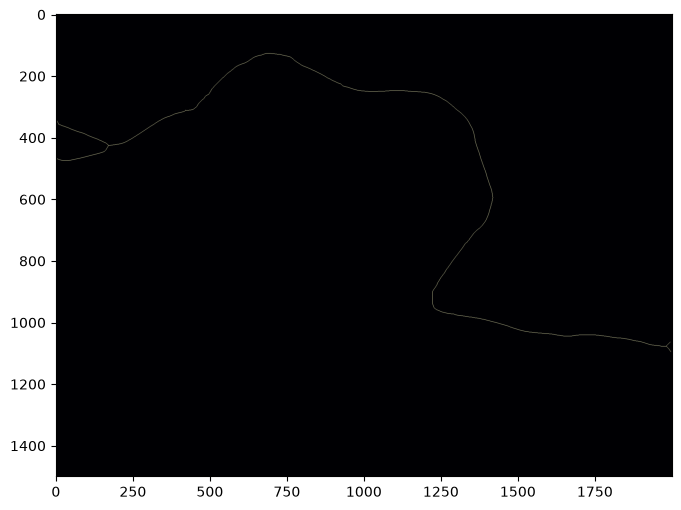

199.5391052434012
[463   0]
[426 171]
209.48023074035552
[341   1]
[425 171]
24.213203435596434
[1077 1982]
[1095 1997]
2629.441917710331
[311 422]
[1077 1981]
18.384776310850242
[1076 1982]
[1063 1995]
296.2203461105335
[425 172]
[311 421]


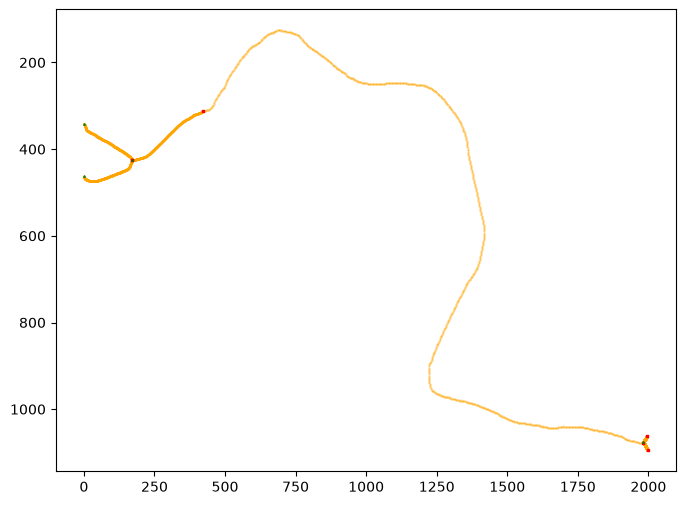

In [4]:
import numpy as np
import networkx as nx
from scipy.interpolate import splprep, splev
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree


def extend_path_ends(path_coords, extend_distance_meters=15.0, resolution=10.0):
    """
    利用首尾两端的局部切向量，将路径两端各外推延伸指定的物理距离（米）
    :param path_coords: 像素级坐标数组 (N, 2)，格式为 (y, x)
    :param extend_distance_meters: 期望外推的物理距离（单位：米）
    :param resolution: 图像分辨率（单位：米/像素，默认 10.0）
    :return: 延伸后的像素坐标数组
    """
    if len(path_coords) < 3:
        return path_coords
        
    path_coords = np.array(path_coords, dtype=float)
    
    # 将物理距离（米）转换为像素单位
    extend_distance_pixels = extend_distance_meters / resolution
    
    # 1. 处理起点（向外倒推延伸）
    v_start = path_coords[1] - path_coords[0]
    norm_start = np.linalg.norm(v_start)
    if norm_start > 1e-5:
        t_start = v_start / norm_start
        new_start = path_coords[0] - t_start * extend_distance_pixels
        path_coords = np.insert(path_coords, 0, new_start, axis=0)
        
    # 2. 处理终点（向前顺延延伸）
    v_end = path_coords[-1] - path_coords[-2]
    norm_end = np.linalg.norm(v_end)
    if norm_end > 1e-5:
        t_end = v_end / norm_end
        new_end = path_coords[-1] + t_end * extend_distance_pixels
        path_coords = np.vstack([path_coords, new_end])
    
    
    return path_coords



def build_spline_network(binary_skeleton, flow_vector=(1, 0.5), smoothing=5.0):
    """
    构建骨架样条网络：
    1. 保留交汇点（Junctions），使相邻分支在交汇处无缝连续，无断开缺口。
    2. 基于全局 flow_vector 投影，严格统一所有支路从上游到下游的起点/终点方向。
    
    :param binary_skeleton: 连续无断裂的单像素二值骨架图
    :param flow_vector: 宏观河流流向向量 (fx, fy)，对应 (x, y) 坐标系
    :param smoothing: 样条拟合的平滑系数 (s值)
    :return: 包含所有独立样条参数方程的字典
    """
    # 1. 提取骨架点并建立无向图
    y_idx, x_idx = np.where(binary_skeleton > 0)
    point_set = set(zip(y_idx, x_idx))
    
    G = nx.Graph()
    for y, x in point_set:
        for dy, dx in [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]:
            nb = (y + dy, x + dx)
            if nb in point_set:
                G.add_edge((y, x), nb)
                
    if G.number_of_edges() == 0:
        return {}

    # 2. 识别特殊节点：端点 (degree == 1) 和交汇点 (degree >= 3)
    endpoints = {n for n, d in G.degree() if d == 1}
    junctions = {n for n, d in G.degree() if d >= 3}
    
    
    #     # 3. 聚类合并交汇簇（核心修复）
    # if len(junctions_raw) > 0:
    #     junc_list = list(junctions_raw)
    #     junc_arr = np.array(junc_list)
    #     tree = cKDTree(junc_arr)
        
    #     # 距离 ≤ 3 像素的视为同一簇
    #     pairs = tree.query_pairs(r=3)
        
    #     # 并查集合并
    #     parent = {i: i for i in range(len(junc_list))}
    #     def find(x):
    #         while parent[x] != x:
    #             parent[x] = parent[parent[x]]
    #             x = parent[x]
    #         return x
    #     def union(a, b):
    #         pa, pb = find(a), find(b)
    #         if pa != pb:
    #             parent[pb] = pa
        
    #     for i, j in pairs:
    #         union(i, j)
        
    #     # 按簇分组
    #     clusters = {}
    #     for i in range(len(junc_list)):
    #         root = find(i)
    #         clusters.setdefault(root, []).append(junc_list[i])
        
    #     # 每簇取几何中心作为唯一交汇点
    #     junctions = set()
    #     for pts in clusters.values():
    #         center = tuple(np.mean(pts, axis=0).astype(int))
    #         junctions.add(center)
        
    #     print(f"交汇簇合并: {len(junctions_raw)} → {len(junctions)} 个交汇点")
    # else:
    #     junctions = set()
    
    
    
    
    special_nodes = endpoints | junctions
    
    if not special_nodes:
        special_nodes = {list(G.nodes())[0]}

    # 3. 提取特殊节点之间的所有无分叉支路段
    segments = []
    visited_edges = set()

    for u in special_nodes:
        for v in G[u]:
            edge = tuple(sorted([u, v]))
            if edge in visited_edges:
                continue
            
            path = [u, v]
            visited_edges.add(edge)
            
            curr = v
            prev = u
            while curr not in special_nodes and G.degree(curr) == 2:
                next_nodes = [nb for nb in G[curr] if nb != prev]
                if not next_nodes:
                    break
                nxt = next_nodes[0]
                next_edge = tuple(sorted([curr, nxt]))
                visited_edges.add(next_edge)
                path.append(nxt)
                prev = curr
                curr = nxt
            
            segments.append(path)

    flow_fx, flow_fy = flow_vector
    spline_network = {}
    
    for seg_id, path_nodes in enumerate(segments):
        if len(path_nodes) < 3:
            continue
            
        path_coords = np.array(path_nodes)  # shape: (N, 2), 格式为 (y, x)
        
        # 4. 【核心改进】：基于宏观 flow_vector 投影严格统一流向
        # path_coords[0] 为起点 (y0, x0)，path_coords[-1] 为终点 (y1, x1)
        # 转换为 (x, y) 坐标计算在 flow_vector 上的投影
        start_x, start_y = path_coords[0, 1], path_coords[0, 0]
        end_x, end_y = path_coords[-1, 1], path_coords[-1, 0]
        
        proj_start = start_x * flow_fx + start_y * flow_fy
        proj_end = end_x * flow_fx + end_y * flow_fy
        
        # 如果终点的投影小于起点，说明该支路方向逆流，必须翻转顺序
        if proj_end < proj_start:
            path_coords = path_coords[::-1]
        
        # path_coords_extended = extend_path_ends(path_coords, extend_distance_meters=20.0, resolution=10.0)
        # # 3. 【核心裁剪】：使用 np.clip 限制坐标不超出图像边界 (H, W)
        # H, W = binary_skeleton.shape
        
        # # path_coords_extended[:, 0] 对应 y 轴（行），限制在 [0, H-1]
        # path_coords_extended[:, 0] = np.clip(path_coords_extended[:, 0], 0.0, float(H - 1))
        # # path_coords[:, 1] 对应 x 轴（列），限制在 [0, W-1]
        # path_coords_extended[:, 1] = np.clip(path_coords_extended[:, 1], 0.0, float(W - 1))
    

        
        # 5. 清理微小重复点，计算累积弧长参数 s
        diffs = np.diff(path_coords, axis=0)
        # diffs = np.diff(path_coords_extended, axis=0)
        segment_lengths = np.linalg.norm(diffs, axis=1)
        valid_mask = np.insert(segment_lengths > 1e-5, 0, True)
        if np.sum(valid_mask) < 4:
            continue
        # path_coords_clean = path_coords_extended[valid_mask]
        path_coords_clean = path_coords[valid_mask]
        
        diffs_clean = np.diff(path_coords_clean, axis=0)
        s_params_clean = np.insert(np.cumsum(np.linalg.norm(diffs_clean, axis=1)), 0, 0)
        
        x_coords = path_coords_clean[:, 1]
        y_coords = path_coords_clean[:, 0]
        
        # 6. 三次样条拟合 (B-Spline)
        try:
            tck, u = splprep([x_coords, y_coords], u=s_params_clean, s=smoothing, k=3)
        except Exception:
            continue
        
        if s_params_clean[-1] < 10.0:
            continue
        
        spline_network[f"segment_{seg_id}"] = {
            "tck": tck,                      # 样条方程核心参数
            "length": s_params_clean[-1],    # 该分支的物理总长度
            "start_pt": path_coords_clean[0],  # 锚点起点 (y, x) 严格位于上游
            "end_pt": path_coords_clean[-1]    # 锚点终点 (y, x) 严格位于下游
        }
        
    return spline_network, junctions

        


# 使用方法：
# flow_dir = (1, 0.5) # 假设河流整体向右下流
# splines = build_spline_network(continuous_skeleton, flow_vector=flow_dir)




def plot_spline_segment(segment_data, num_points=500):
    """
    基于 tck 参数方程和总长度，绘制单段航道样条曲线
    
    :param segment_data: 字典，包含 'tck', 'length', 'start_pt', 'end_pt'
    :param num_points: 想要在曲线上采样的点数（决定曲线的平滑度）
    """
    tck = segment_data["tck"]
    total_length = segment_data["length"]
    start_pt = segment_data["start_pt"]
    end_pt = segment_data["end_pt"]
    
    # 1. 构建连续的弧长参数 s
    # 在 [0, total_length] 区间内均匀生成 num_points 个参数点
    s_eval = np.linspace(0, total_length, num_points)
    
    # 2. 将参数 s 代入 tck 方程，求出对应的离散 x, y 坐标
    # splev 会自动解析 tck 并返回 (x_array, y_array)
    coords_eval = splev(s_eval, tck)
    x_eval = coords_eval[0]
    y_eval = coords_eval[1]
    
    return coords_eval
    # 3. 开始绘图
    # plt.figure(figsize=(10, 8))
    
    # # 画出连续的拟合曲线
    # plt.plot(x_eval, y_eval, color='blue', linewidth=2, label=f"Spline Curve (Len: {total_length:.1f})")
    
    # # 标出起点和终点，验证流向对齐是否成功
    # # 注意：我们之前的 start_pt 格式是 (y, x)，绘图时通常是 (x, y)
    # plt.scatter(start_pt[1], start_pt[0], color='green', s=100, marker='^', zorder=5, label='Start Node')
    # plt.scatter(end_pt[1], end_pt[0], color='red', s=100, marker='s', zorder=5, label='End Node')
    
    # # 如果你想看看均匀采样的点长什么样，可以把下面这行取消注释
    # # plt.scatter(x_eval, y_eval, color='orange', s=10, alpha=0.5, label='Sampled Points')
    
    # # 设置图像翻转 (如果是图像坐标系，原点在左上角，Y轴向下)
    # plt.gca().invert_yaxis() 
    
    # plt.title("Parametric Spline Trajectory Visualization")
    # plt.xlabel("X Coordinate")
    # plt.ylabel("Y Coordinate")
    # plt.legend()
    # plt.grid(True, linestyle='--', alpha=0.6)
    # plt.axis('equal') # 保证 X 轴和 Y 轴比例一致，不发生几何形变
    # plt.show()

# ==========================================
# 调用示例：
# ==========================================
# 假设你之前提取的字典叫 spline_network，想画出名为 'segment_0' 的分支
# target_segment = spline_network["segment_0"]
# plot_spline_segment(target_segment, num_points=1000)

if __name__ == '__main__':
    skeleton = np.load('./skeleton_small.npy')
    # skeleton = skeleton[2258:2400, 3000:3140]
    
    # heatmap = np.load('./smoothed.npy')
    plt.figure(figsize=(8, 6))
    plt.imshow(skeleton, cmap='magma')
    plt.show()
    
    spline_network, junctions = build_spline_network(skeleton, flow_vector=(1, 0.5), smoothing=5.0)
    
    # total_coords = []
    plt.figure(figsize=(8, 6))
    for key in spline_network.keys():

        target_segment = spline_network[key]
        total_length = target_segment["length"]
        start_pt = target_segment["start_pt"]
        end_pt = target_segment["end_pt"]
        
        print(total_length)
        print(start_pt)
        print(end_pt)
        
        cordi = plot_spline_segment(target_segment, num_points=1000)
        # total_coords.append(cordi)
        x_eval = cordi[0]
        y_eval = cordi[1]

        # plt.plot(x_eval, y_eval, color='blue', linewidth=2, label=f"Spline Curve (Len: {total_length:.1f})")
   
        plt.scatter(start_pt[1], start_pt[0], color='green', s=1, marker='^', zorder=5, label='Start Node')
        plt.scatter(end_pt[1], end_pt[0], color='red', s=1, marker='s', zorder=5, label='End Node')
        plt.scatter(x_eval, y_eval, color='orange', s=0.2, alpha=0.5, label='Sampled Points')
        
        
    plt.gca().invert_yaxis() 
    plt.show()


length: 255.1198410471446
start_pt: [1696.58578644 3097.58578644]
end_pt: [1885.41421356 3236.41421356]
new_ds: 8.229672291843375
s_eval: 4.114836145921688
s_eval: 12.344508437765063
s_eval: 20.574180729608436


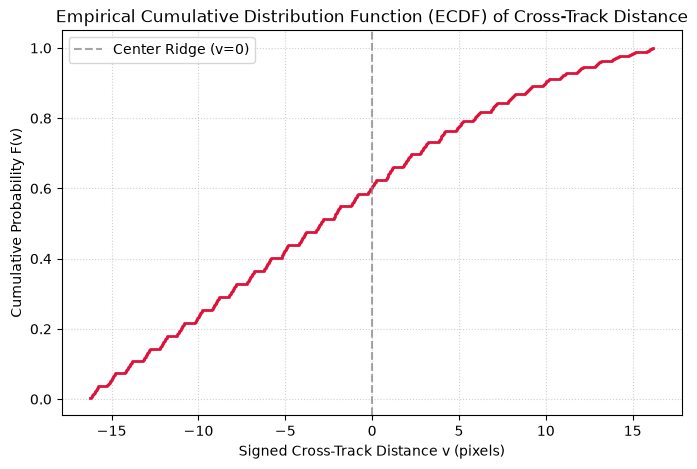

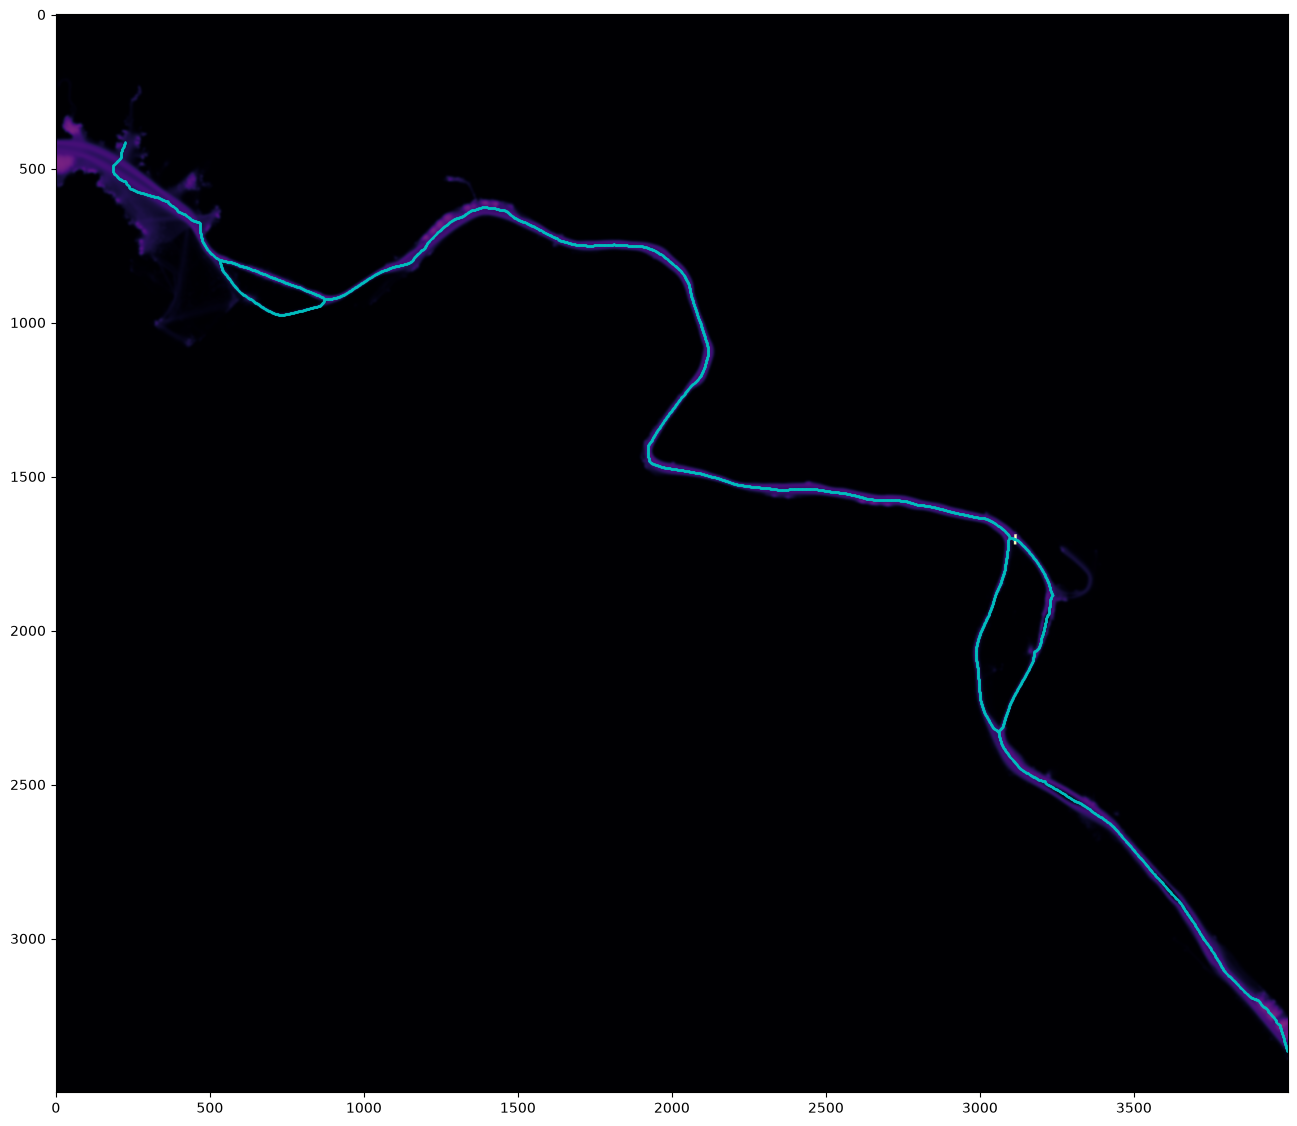

In [2]:


from scipy.interpolate import splprep, splev
import numpy as np


import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import splev

def analyze_local_cross_track_ecdf(tck, s, heatmap, L=4.0, W=8.0, weighted=True):
    """
    计算脊线在弧长 s 处局部区域 T 内点的带符号跨轨距离及其经验累积分布函数 (ECDF)
    
    :param tck: scipy 三次样条方程参数 (t, c, k)
    :param s: 给定的弧长参数值 (0 <= s <= total_length)
    :param heatmap: 2D 热力图 numpy 矩阵，heatmap[y, x] 表示坐标 (x, y) 处的热力强度
    :param L: 管状区域 T 沿切线方向的总长度，半长
    :param W: 管状区域 T 沿法线方向的半宽度 (总宽度为 2*W)
    :param weighted: True 时使用热力图像素值作为权重计算加权 ECDF，False 为标准 ECDF
    :return: 包含局部几何参数、跨轨距离及 ECDF 曲线数据的字典
    """
    # 1. 计算 s 处的中心点 P(s) 与一阶导数 P'(s)
    P = splev(s, tck, der=0)    # [x(s), y(s)]
    dP = splev(s, tck, der=1)   # [x'(s), y'(s)]
    
    x0, y0 = P[0], P[1]
    dx, dy = dP[0], dP[1]
    
    # 2. 计算单位切向量 T 与单位法向量 N
    norm_t = np.hypot(dx, dy)
    if norm_t == 0:
        raise ValueError(f"弧长 s={s} 处的导数为 0，无法确定切线方向。")
    
    # 将切向量归一化为单位向量
    Tx, Ty = dx / norm_t, dy / norm_t
    # 逆时针旋转 90 度作为法向
    Nx, Ny = -Ty, Tx  
    
    # 3. 建立局部 ROI 包围盒以加速像素提取
    max_r = np.sqrt(L**2 + W**2)
    H, W = heatmap.shape
    
    min_x = int(np.clip(np.floor(x0 - max_r), 0, W - 1))
    max_x = int(np.clip(np.ceil(x0 + max_r), 0, W - 1))
    min_y = int(np.clip(np.floor(y0 - max_r), 0, H - 1))
    max_y = int(np.clip(np.ceil(y0 + max_r), 0, H - 1))
    
    # 4. 生成 ROI 区域内的网格像素坐标
    grid_x, grid_y = np.meshgrid(np.arange(min_x, max_x + 1), np.arange(min_y, max_y + 1))
    
    # 计算相对向量 V = Q - P(s)
    Vx = grid_x - x0
    Vy = grid_y - y0
    
    # 投影到切线与法线方向
    u = Vx * Tx + Vy * Ty  # 沿轨距离 (along-track)
    v = Vx * Nx + Vy * Ny  # 跨轨距离 (cross-track, 带符号)
    
    # 5. 筛选落在管状区域 T 内的点 (|u| <= L 且 |v| <= W)
    inside_mask = (np.abs(u) <= L) & (np.abs(v) <= W)
    
    # valid_v是1维数组，包含所有落在区域 T 内的跨轨距离
    valid_v = v[inside_mask]
    
    # grid_y[inside_mask]和grid_x[inside_mask]是对应的像素坐标，用于从热力图中提取权重
    valid_weights = heatmap[grid_y[inside_mask], grid_x[inside_mask]]
    
    if len(valid_v) == 0:
        raise ValueError(f"在 s={s} 处的区域 T 内未检测到任何像素点，请适当调大 L 或 W。")
        
    # 6. 计算经验累积分布函数 (ECDF)
    sort_idx = np.argsort(valid_v)
    sorted_v = valid_v[sort_idx]
    sorted_weights = valid_weights[sort_idx]
    
    if weighted and np.sum(sorted_weights) > 0:
        # 基于热力图权重的累积概率分布
        cum_weights = np.cumsum(sorted_weights)
        ecdf_y = cum_weights / cum_weights[-1]
    else:
        # 离散点的标准未加权 ECDF
        ecdf_y = np.arange(1, len(sorted_v) + 1) / len(sorted_v)
        
    return {
        "center": (x0, y0),
        "tangent": (Tx, Ty),
        "normal": (Nx, Ny),
        "cross_track_distances": sorted_v,
        "ecdf_x": sorted_v,
        "ecdf_y": ecdf_y,
        "weights": sorted_weights,
        "inside_coords": (grid_x[inside_mask], grid_y[inside_mask])
    }

def plot_ecdf_results(analysis_res):
    """ 绘制带符号跨轨距离的 ECDF 曲线 """
    plt.figure(figsize=(8, 5))
    plt.step(analysis_res["ecdf_x"], analysis_res["ecdf_y"], where='post', color='crimson', linewidth=2)
    plt.axvline(0, color='gray', linestyle='--', alpha=0.7, label='Center Ridge (v=0)')
    plt.title("Empirical Cumulative Distribution Function (ECDF) of Cross-Track Distance")
    plt.xlabel("Signed Cross-Track Distance v (pixels)")
    plt.ylabel("Cumulative Probability F(v)")
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend()
    plt.show()

# ==========================================
# 使用示例：
# ==========================================
# 假设已获取某段样条方程 tck，在弧长 s=150.0 处提取 L=50, W=25 的区域
# res = analyze_local_cross_track_ecdf(target_segment["tck"], s=150.0, heatmap=raw_heatmap, L=50.0, W=25.0)
# plot_ecdf_results(res)



L = 4
W = 10
weighted = True
# heatmap = np.load('./heatmap.npy')
# heatmap = np.flip(heatmap, axis=0)
# heatmap = np.log1p(heatmap)
# print(heatmap.max())
# heatmap = heatmap[2258:2400, 3000:3140]
heatmap = np.load('./smoothed.npy')

for key in spline_network.keys():
    segment = spline_network[key]
    length = segment["length"]
    print('length:', length)
    print('start_pt:', segment["start_pt"])
    print('end_pt:', segment["end_pt"])
    
    tck = segment["tck"]
    
    ds = 2*L
    
    sub_segment_num = int(length // ds)
    # res = length - ds * sub_segment_num
    new_ds = length/sub_segment_num
    print('new_ds:', new_ds)
    
    s = []
    for i in range(sub_segment_num):
        s.append(new_ds * i+new_ds/2.0)
        
    # s.append(length - res/2.0)
    
    count = 0
    for s_eval in s:
        count += 1
        print('s_eval:', s_eval)
        
        analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=new_ds/2.0, W=15.0, weighted=True)
        # if count<len(s):
        #     analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=4.0, W=8.0, weighted=True)

        # else:
        #     analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=res/2.0, W=8.0, weighted=True)
        
        # plot_ecdf_results(analysis_res)
        # print(analysis_res['inside_coords'])
        
        if count==3:
            plot_ecdf_results(analysis_res)
            inside_x, inside_y = analysis_res['inside_coords']
            for i in range(len(inside_x)):
                x = inside_x[i]
                y = inside_y[i]
                
                # print('x:', x, 'y:', y)
                heatmap[y, x] = 30
            break    
    
    break

y_coords, x_coords = np.where(skeleton)
coords = np.column_stack((x_coords, y_coords))


plt.figure(figsize=(16, 14))
# plt.imshow(heatmap[900:1000, 850:950], cmap='magma')
plt.imshow(heatmap, cmap='magma')
plt.plot(coords[:, 0], coords[:, 1], 'c.', markersize=1)
plt.show()


In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt, savgol_filter
from scipy.interpolate import splprep, splev

def ultimate_smooth_fairway_boundaries(s_grid, centers, normals, left_pts, right_pts,
                                      med_kernel=5, sg_window=15, sg_poly=2, spline_s=10.0):
    """
    终极平滑方案：中值滤波去噪 + 法线角度平滑 + 2D B-Spline 参数重拟合
    
    :param s_grid: 弧长网格 (S,)
    :param centers: 脊线中心点 (S, 2)
    :param normals: 脊线原始单位法向量 (S, 2)
    :param left_pts: 原始左边界像素坐标数组 (S, 2)
    :param right_pts: 原始右边界像素坐标数组 (S, 2)
    :param v_left_raw: 原始 1D 左跨轨距离数组 (S,)
    :param v_right_raw: 原始 1D 右跨轨距离数组 (S,)
    :param med_kernel: 中值滤波核大小 (奇数)，用于直接剔除 ECDF 离群野点
    :param sg_window: SG 滤波器窗口 (奇数)
    :param sg_poly: SG 多项式阶数
    :param spline_s: 2D B-Spline 的平滑因子 (越大多项式越平滑，剔除微小折线)
    """
    s_grid = np.asarray(s_grid)
    centers = np.asarray(centers)
    normals = np.asarray(normals)
    left_pts = np.asarray(left_pts)
    right_pts = np.asarray(right_pts)
    
    # 0. 反算原始的 1D 跨轨距离 v_left 和 v_right
    # v = (Point - Center) · Normal
    vec_left = left_pts - centers
    vec_right = right_pts - centers
    
    print("left_pts:", left_pts.shape)
    print("centers:", centers.shape)
    print("normals:", normals.shape)
    print("vec_left:", vec_left.shape)
    
    v_left_raw = np.sum(vec_left * normals, axis=1)
    v_right_raw = np.sum(vec_right * normals, axis=1)
    
    # -------------------------------------------------------------------------
    # 1. 第一击：平滑法线角度 $\theta(s)$，解决上下边界同步突折的根本问题
    # -------------------------------------------------------------------------
    # 将法向量转化为连续角度 (使用 unwrap 解决 -pi 到 pi 的跳跃)
    angles = np.arctan2(normals[:, 1], normals[:, 0])
    angles_unwrapped = np.unwrap(angles)
    
    # 对角度进行平滑，确保法向平稳旋转
    print("点数:", len(angles_unwrapped), "sg_window:", sg_window)
    angles_smooth = savgol_filter(angles_unwrapped, window_length=sg_window, polyorder=sg_poly)
    
    # 重构平滑后的单位法向量
    normals_smooth = np.column_stack([np.cos(angles_smooth), np.sin(angles_smooth)])
    
    # -------------------------------------------------------------------------
    # 2. 第二击：1D 信号预处理 (中值滤波去野点 + SG 滤波)
    # -------------------------------------------------------------------------
    def smooth_1d_signal(v_raw):
        # 先用中值滤波瞬间杀掉单点野点 (Outlier)
        v_med = medfilt(v_raw, kernel_size=med_kernel)
        # 再用 SG 滤波做平滑
        return savgol_filter(v_med, window_length=sg_window, polyorder=sg_poly)
        
    v_left_sm = smooth_1d_signal(v_left_raw)
    v_right_sm = smooth_1d_signal(v_right_raw)
    
    # 初步合成 2D 点集
    left_2d_raw = centers + v_left_sm[:, np.newaxis] * normals_smooth
    right_2d_raw = centers + v_right_sm[:, np.newaxis] * normals_smooth
    
    # -------------------------------------------------------------------------
    # 3. 第三击：2D 几何空间 B-Spline 参数化重拟合 (彻底消除 Z 字形打结)
    # -------------------------------------------------------------------------
    def re_spline_2d(pts_2d, smoothing):
        # 移除空间距离过近的重叠点 (防止 splprep 报错)
        dists = np.sqrt(np.sum(np.diff(pts_2d, axis=0)**2, axis=1))
        keep_mask = np.insert(dists > 1e-3, 0, True)
        clean_pts = pts_2d[keep_mask]
        
        if len(clean_pts) < 4:
            return pts_2d
            
        x, y = clean_pts[:, 0], clean_pts[:, 1]
        
        # 参数化 2D 样条拟合，s 参量控制平滑度
        tck, u = splprep([x, y], s=smoothing, k=3)
        
        # 按照原点数重新等间距采样，生成极度顺滑的曲线
        u_fine = np.linspace(0, 1, len(pts_2d))
        x_smooth, y_smooth = splev(u_fine, tck)
        return np.column_stack([x_smooth, y_smooth])

    left_2d_final = re_spline_2d(left_2d_raw, smoothing=spline_s)
    right_2d_final = re_spline_2d(right_2d_raw, smoothing=spline_s)
    
    return left_2d_final, right_2d_final

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.60):
    """
    基于局部管状区域的 ECDF 输出，计算指定置信度水平的航道跨轨范围及全局图像坐标
    
    :param analysis_res: analyze_local_cross_track_ecdf 函数输出的字典
    :param confidence_level: 置信度水平 (0 < confidence_level < 1)，如 0.60 代表 60%
    :return: 包含三种策略下跨轨距离区间及对应全局 (X, Y) 坐标的字典
    """
    ecdf_x = np.array(analysis_res["ecdf_x"]) # 排序后的跨轨距离 v
    ecdf_y = np.array(analysis_res["ecdf_y"]) # 对应的累积概率 CDF(v)
    
    x0, y0 = analysis_res["center"]
    Nx, Ny = analysis_res["normal"]
    
    p = confidence_level
    if not (0 < p < 1):
        raise ValueError("置信度水平 confidence_level 必须在 (0, 1) 区间内。")
        
    results = {}

    # =========================================================================
    # 策略 1: 等尾分位数对称包络 (Equal-tailed Quantile Interval)
    # =========================================================================
    p_low = (1.0 - p) / 2.0
    p_high = 1.0 - p_low
    
    v_min_eq = np.interp(p_low, ecdf_y, ecdf_x)
    v_max_eq = np.interp(p_high, ecdf_y, ecdf_x)
    
    results["equal_tailed"] = {
        "v_range": (v_min_eq, v_max_eq),
        "width": v_max_eq - v_min_eq,
        'center': (x0, y0),
        "pt_min": (x0 + v_min_eq * Nx, y0 + v_min_eq * Ny),
        "pt_max": (x0 + v_max_eq * Nx, y0 + v_max_eq * Ny),
        'normal': (Nx, Ny)
    }

    # =========================================================================
    # 策略 2: 基于脊线 v=0 的零点对称包络 (Zero-Centered Symmetric Interval)
    # =========================================================================
    # 计算绝对距离 |v| 的累积概率分布
    abs_v = np.abs(ecdf_x)
    sort_abs_idx = np.argsort(abs_v)
    sorted_abs_v = abs_v[sort_abs_idx]
    
    # 重新计算绝对距离的加权/非加权 ECDF
    weights = np.array(analysis_res["weights"])[sort_abs_idx]
    if np.sum(weights) > 0:
        cum_abs_y = np.cumsum(weights) / np.cumsum(weights)[-1]
    else:
        cum_abs_y = np.arange(1, len(sorted_abs_v) + 1) / len(sorted_abs_v)
        
    r_sym = np.interp(p, cum_abs_y, sorted_abs_v)
    
    results["zero_symmetric"] = {
        "v_range": (-r_sym, r_sym),
        "width": 2 * r_sym,
        'center': (x0, y0),
        "pt_min": (x0 - r_sym * Nx, y0 - r_sym * Ny),
        "pt_max": (x0 + r_sym * Nx, y0 + r_sym * Ny),
        'normal': (Nx, Ny)
    }

    # =========================================================================
    # 策略 3: 非对称最小宽度包络 (Asymmetric / Highest Density Interval - HDI)
    # =========================================================================
    # 向量化寻找所有满足 ΔCDF >= p 的 index 组合中，Δv 最小的一组
    j_indices = np.searchsorted(ecdf_y, ecdf_y + p, side='left')
    valid_mask = j_indices < len(ecdf_y)
    
    if np.any(valid_mask):
        valid_i = np.where(valid_mask)[0]
        valid_j = j_indices[valid_mask]
        
        widths = ecdf_x[valid_j] - ecdf_x[valid_i]
        best_idx = np.argmin(widths)
        
        v_min_asym = ecdf_x[valid_i[best_idx]]
        v_max_asym = ecdf_x[valid_j[best_idx]]
    else:
        # 退化边界情况
        v_min_asym, v_max_asym = ecdf_x[0], ecdf_x[-1]

    results["asymmetric_hdi"] = {
        "v_range": (v_min_asym, v_max_asym),
        "width": v_max_asym - v_min_asym,
        'center': (x0, y0),
        "pt_min": (x0 + v_min_asym * Nx, y0 + v_min_asym * Ny),
        "pt_max": (x0 + v_max_asym * Nx, y0 + v_max_asym * Ny),
        'normal': (Nx, Ny)
    }

    return results

def print_and_plot_boundaries(analysis_res, bounds_res, confidence_level=0.60):
    """ 输出包络数值并绘制 ECDF 置信区间示意图 """
    print(f"=== 弧长 s 处置信度为 {confidence_level*100:.0f}% 的航道范围计算结果 ===")
    for strategy_name, res in bounds_res.items():
        v_min, v_max = res["v_range"]
        print(f"[{strategy_name}]")
        print(f"  跨轨范围 (v): [{v_min:.2f}, {v_max:.2f}] 像素")
        print(f"  包络总物理宽度: {res['width']:.2f} 像素")
        print(f"  左界图像坐标: ({res['pt_max'][0]:.1f}, {res['pt_max'][1]:.1f})")
        print(f"  右界图像坐标: ({res['pt_min'][0]:.1f}, {res['pt_min'][1]:.1f})")
        print("-" * 50)
        
    # 可视化比较
    plt.figure(figsize=(9, 5))
    plt.step(analysis_res["ecdf_x"], analysis_res["ecdf_y"], color='gray', alpha=0.6, label='ECDF')
    
    # 画出 HDI 非对称区间的包络线
    v_a_min, v_a_max = bounds_res["asymmetric_hdi"]["v_range"]
    plt.axvspan(v_a_min, v_a_max, color='orange', alpha=0.25, label=f'Asymmetric HDI ({confidence_level*100:.0f}%)')
    
    # 画出等尾对称区间的虚线
    v_e_min, v_e_max = bounds_res["equal_tailed"]["v_range"]
    plt.axvline(v_e_min, color='blue', linestyle='--', label=f'Equal-tailed Bounds')
    plt.axvline(v_e_max, color='blue', linestyle='--')
    
    # 画出零点对称包络
    v_z_min, v_z_max = bounds_res["zero_symmetric"]["v_range"]
    plt.axvline(v_z_min, color='cyan', linestyle='--', label=f'Zero-Symmetric Bounds')
    plt.axvline(v_z_max, color='cyan', linestyle='--')
    
    plt.axvline(0, color='red', linestyle=':', label='Center Ridge (v=0)')
    plt.title(f"Cross-Track ECDF with {confidence_level*100:.0f}% Confidence Intervals")
    plt.xlabel("Signed Cross-Track Distance v (pixels)")
    plt.ylabel("Cumulative Probability F(v)")
    plt.legend()
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# ==========================================
# 调用示例：
# ==========================================
# 假设 analysis_res 为前面单点局部分析的输出结果
# if __name__ == '__main__':
    # bounds = compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.70)
    # print_and_plot_boundaries(analysis_res, bounds, confidence_level=0.70)

In [5]:
import json
from shapely.geometry import Polygon, LineString, Point
from shapely.ops import unary_union

L = 4
W = 10
weighted = True
# heatmap = np.load('./heatmap.npy')
# heatmap = np.flip(heatmap, axis=0)
# heatmap = np.log1p(heatmap)
heatmap = np.load('./smoothed.npy')

print(heatmap.max())


polygons = []
polygons_l = []
polygons_r = []

for key in spline_network.keys():
    segment = spline_network[key]
    length = segment["length"]
    print('length:', length)
    print('start_pt:', segment["start_pt"])
    print('end_pt:', segment["end_pt"])
    
    tck = segment["tck"]
    
    ds = 2*L
    
    sub_segment_num = int(length // ds)
    # res = length - ds * sub_segment_num
    new_ds = length/sub_segment_num
    print('new_ds:', new_ds)
    
    s = []
    for i in range(sub_segment_num):
        s.append(new_ds * i+new_ds/2.0)
        
    # s.append(length - res/2.0)
    
    count = 0
    one_polygon_l  = []
    one_polygon_r  = []
    one_polygon_c = []
    one_polygon_n = []
    for s_eval in s:
        count += 1
        print('s_eval:', s_eval)
        
        analysis_res = analyze_local_cross_track_ecdf(tck, s_eval, heatmap, L=new_ds/2.0, W=W, weighted=True)
        
        bounds = compute_fairway_confidence_boundaries(analysis_res, confidence_level=0.80)
        
        # {
        # "v_range": (-r_sym, r_sym),
        # "width": 2 * r_sym,
        # "pt_min": (x0 - r_sym * Nx, y0 - r_sym * Ny),
        # "pt_max": (x0 + r_sym * Nx, y0 + r_sym * Ny)
        # }
        bounds_asym = bounds["asymmetric_hdi"]
        # bounds_zero_sym = bounds["zero_symmetric"]
        
        # bounds_equ_tailed = bounds["equal_tailed"]
        

        # point_l = bounds_zero_sym["pt_max"]
        # point_r = bounds_zero_sym["pt_min"]
        # point_c = bounds_zero_sym["center"]
        # point_n = bounds_zero_sym["normal"]
        
        point_l = bounds_asym["pt_max"]
        point_r = bounds_asym["pt_min"]
        point_c = bounds_asym["center"]
        point_n = bounds_asym["normal"]
        
        one_polygon_l.append(point_l)
        one_polygon_r.append(point_r)
        one_polygon_c.append(point_c)
        one_polygon_n.append(point_n)
        
    polygons.append(one_polygon_l+one_polygon_r[::-1])
    # polygons_l.append(one_polygon_l)
    # polygons_r.append(one_polygon_r)
    
    # smooth_fairway_boundaries(s_grid, left_pts, right_pts, centers, normals, window_length=11, polyorder=2):
    """
    基于 1D 跨轨距离 signal 进行 Savitzky-Golay 平滑并重构 2D 航道边界
    
    :param s_grid: 弧长参数数组 (S,)
    :param left_pts: 原始左边界像素坐标数组 (S, 2)
    :param right_pts: 原始右边界像素坐标数组 (S, 2)
    :param centers: 脊线中心点坐标数组 (S, 2)
    :param normals: 脊线单位法向量数组 (S, 2)
    :param window_length: SG 滤波器窗口大小 (必须为大于 polyorder 的奇数，越大越平滑)
    :param polyorder: 多项式拟合阶数 (通常设为 2 或 3)
    :return: 平滑后的 (left_smooth_2d, right_smooth_2d)
    """
    # left_smooth_2d, right_smooth_2d = smooth_fairway_boundaries(s, one_polygon_l, one_polygon_r, one_polygon_c, one_polygon_n, window_length=21, polyorder=2)
    left_smooth_2d, right_smooth_2d = ultimate_smooth_fairway_boundaries(s, one_polygon_c, one_polygon_n, one_polygon_l, one_polygon_r, med_kernel=5, sg_window=15, sg_poly=2, spline_s=10.0)
    polygons_l.append(left_smooth_2d)
    polygons_r.append(right_smooth_2d)




# orders = [4,5,0,7,6,2]

# aranged_polygons_l = []
# aranged_polygons_r = []
# for order in orders:
#     aranged_polygons_l.extend(polygons_l[order])
#     aranged_polygons_r.extend(polygons_r[order])

# all_points = aranged_polygons_l + aranged_polygons_r[::-1]
# all_points = np.array(all_points)
# all_points = all_points.tolist()



# f = open('./all_points_80_symm_smooth_ultimate_asym.json', 'w')
# json.dump(all_points, f)
# f.close()

# x = [p[0] for p in all_points]
# y = [p[1] for p in all_points]


# plt.figure(figsize=(16, 14))
# # plt.imshow(heatmap[900:1000, 850:950], cmap='magma')
# plt.imshow(heatmap, cmap='magma')

# # 在图像上绘制折线
# plt.plot(x, y, 'o-', markersize=1, linewidth=1, 
#         color='cyan', markerfacecolor='yellow', 
#         markeredgecolor='red', markeredgewidth=0.1)

# # 从第一个点连接到所有其他点
# first_point = all_points[0]
# for point in all_points[1:]:
#     plt.plot([first_point[0], point[0]], [first_point[1], point[1]], 'b--', alpha=0.5, linewidth=1)
#     first_point = point
    
# plt.show()


all_polygons = []
for ii in range(len(polygons_l)):
    pts_left_final = polygons_l[ii]
    pts_right_final = polygons_r[ii]
    poly_pts = np.vstack([pts_left_final, pts_right_final[::-1]])
    ply = Polygon(poly_pts)
    if ply.is_valid and ply.area > 0:
        all_polygons.append(ply)


# # 【核心新增】：针对骨架图中的所有交汇点 (Junctions) 打上“几何补丁”
# # junctions 是在骨架提取阶段识别出的 degree >= 3 的节点集合 (格式为 (y, x) 像素坐标)
# patch_radius_meters = 100.0  # 补丁的物理半径（单位：米），可根据河道宽度微调（例如设为河宽的一半）
# res = 10.0
# patch_radius_pixels = patch_radius_meters / res  # 转换为像素单位

# for junc_y, junc_x in junctions:
#     # 将像素坐标转换为你的图形坐标系 (若你的坐标系是像素坐标则直接用 x, y)
#     # 假设此处使用与支路相同的坐标系转换方式: x = x * res, y = y * res
#     junc_pt_x = junc_x
#     junc_pt_y = junc_y
    
#     # 以交汇点为中心创建一个圆形缓冲区作为“胶水补丁”
#     patch_poly = Point(junc_pt_x, junc_pt_y).buffer(patch_radius_pixels)
#     all_polygons.append(patch_poly)


global_fairway_polygon = unary_union(all_polygons) if all_polygons else Polygon()
print(f"-> 本文方法大范围全流域航道包络提取完成！总面积: {global_fairway_polygon.area:.1f} 平方米。")
if not global_fairway_polygon.is_valid:
    global_fairway_polygon = global_fairway_polygon.buffer(0.0) # 经典的 Shapely 零缓冲区修复法



epsilon = 3.0 # 根据你的坐标系单位（例如米）调整这个值，开始设小一点

# --- 之前不完美的做法 ---
# unified_poly = unary_union(all_segments_polygons) # 这里连接处可能有裂缝

# --- 改进做法（先膨胀强制重叠，再合并，最后收缩） ---

# 1. 膨胀所有分段
buffered_segments = [poly.buffer(epsilon) for poly in all_polygons]

# 2. 合并连成整体
unified_buffered_poly = unary_union(buffered_segments)

# 3. 收缩回原来宽度（消除整体膨胀，保留连接）
global_fairway_polygon_filled = unified_buffered_poly.buffer(-epsilon)



11.082793393342284
length: 255.1198410471446
start_pt: [1696.58578644 3097.58578644]
end_pt: [1885.41421356 3236.41421356]
new_ds: 8.229672291843375
s_eval: 4.114836145921688
s_eval: 12.344508437765063
s_eval: 20.574180729608436
s_eval: 28.803853021451815
s_eval: 37.033525313295186
s_eval: 45.26319760513856
s_eval: 53.49286989698194
s_eval: 61.722542188825315
s_eval: 69.95221448066869
s_eval: 78.18188677251206
s_eval: 86.41155906435543
s_eval: 94.64123135619882
s_eval: 102.87090364804219
s_eval: 111.10057593988556
s_eval: 119.33024823172894
s_eval: 127.55992052357232
s_eval: 135.7895928154157
s_eval: 144.01926510725906
s_eval: 152.24893739910243
s_eval: 160.4786096909458
s_eval: 168.70828198278917
s_eval: 176.93795427463257
s_eval: 185.16762656647595
s_eval: 193.39729885831932
s_eval: 201.6269711501627
s_eval: 209.85664344200606
s_eval: 218.08631573384943
s_eval: 226.3159880256928
s_eval: 234.5456603175362
s_eval: 242.77533260937957
s_eval: 251.00500490122295
left_pts: (31, 2)
centers:

boundary_polygon: True, MultiPolygon: False


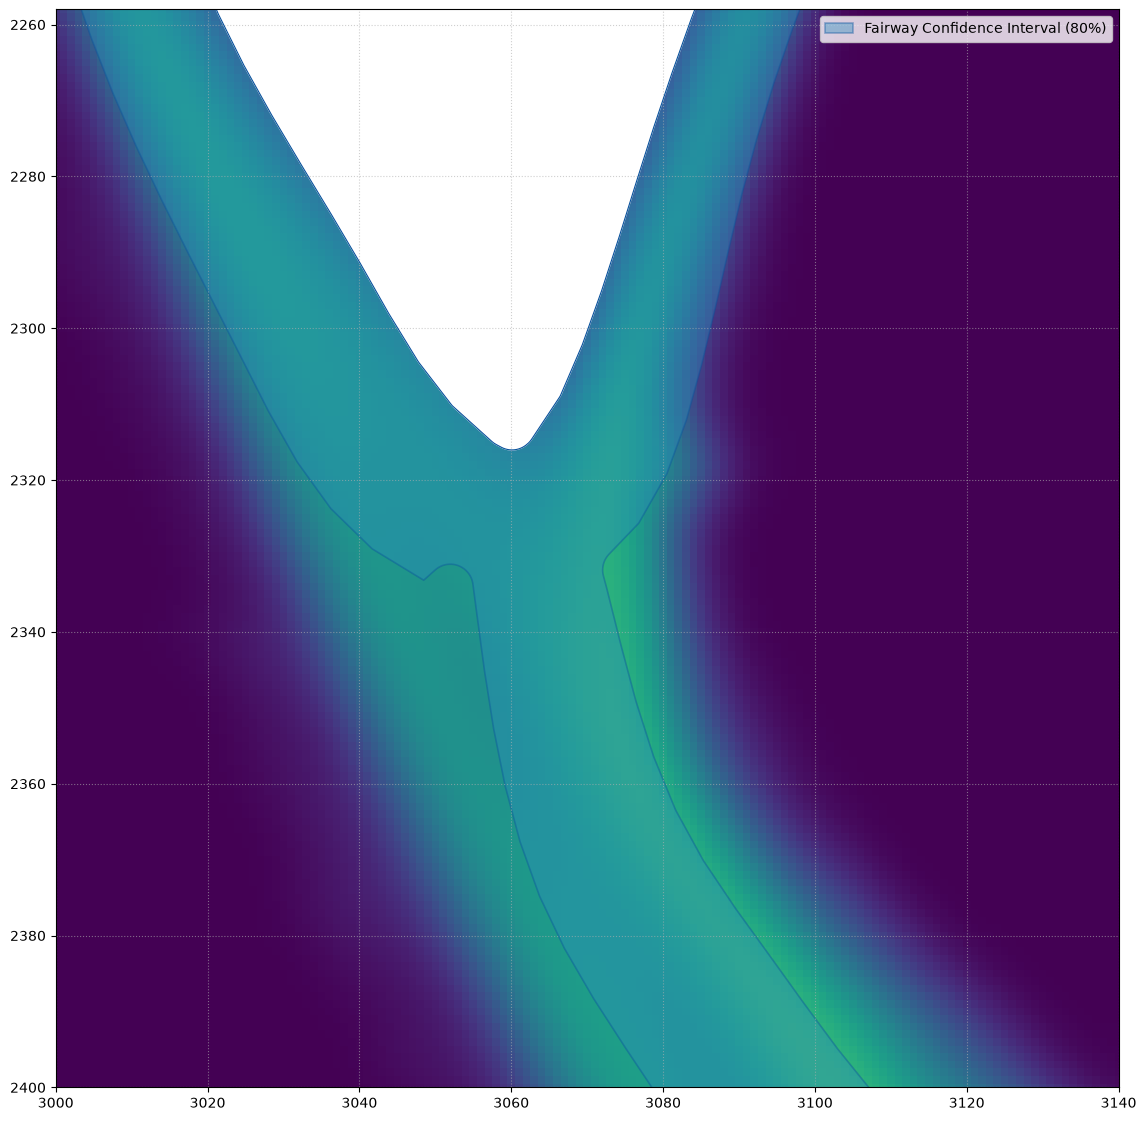

In [7]:
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, MultiPolygon

def plot_fairway_confidence_interval(boundary_polygon, centerline_network=None, trajectory_pts=None, xlim=None, ylim=None):
    """
    绘制大范围航行经验置信区间图形
    """
    # fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    plt.figure(figsize=(16, 14))
    plt.imshow(trajectory_pts, origin='upper')
    ax = plt.gca()
    
    # # 1. 绘制底层 AIS 轨迹点（可选，用于衬托置信范围的契合度）
    # if trajectory_pts is not None:
    #     plt.scatter(trajectory_pts[:, 1], trajectory_pts[:, 0], c='gray', s=0.5, alpha=0.3, label='AIS Trajectories')

    # 2. 解析并绘制 final_boundary_polygon (置信区间包络)
    if boundary_polygon.is_empty:
        print("警告：边界多边形为空！")
        return
        
    # 兼容单多边形 (Polygon) 与复合多边形 (MultiPolygon)
    polys = boundary_polygon.geoms if isinstance(boundary_polygon, MultiPolygon) else [boundary_polygon]
    
    print(f"boundary_polygon: {isinstance(boundary_polygon, Polygon)}, MultiPolygon: {isinstance(boundary_polygon, MultiPolygon)}")
    for idx, poly in enumerate(polys):
        # 提取外边界坐标
        ext_x, ext_y = zip(*poly.exterior.coords)
        # 绘制置信区间填充面
        plt.fill(ext_x, ext_y, color='#2b8cbe', alpha=0.4, edgecolor='#08519c', linewidth=1.2, 
                label='Fairway Confidence Interval (80%)' if idx == 0 else "")
                
        # 处理可能存在的内部岛屿/空洞 (Interiors)
        for interior in poly.interiors:
            int_x, int_y = zip(*interior.coords)
            plt.fill(int_x, int_y, color='white', alpha=1.0) # 用白色或背景色填补内部岛屿
            plt.plot(int_x, int_y, color='#08519c', linewidth=0.8)

    # 3. 绘制中心脊线（若有，用于增强对比）
    if centerline_network is not None:
        for seg_name, data in centerline_network.items():
            tck = data["tck"]
            # 样条重采样绘制中心线
            from scipy.interpolate import splev
            u_vals = np.linspace(0, data["max_u"], 100)
            cx, cy = splev(u_vals, tck)
            plt.plot(cx, cy, color='red', linewidth=1.5, linestyle='--', label='Centerline' if seg_name == 'segment_0' else "")

    
    # 5. 【核心新增】：如果指定了局部显示范围，则应用 xlim 和 ylim
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)
    
    # ax = plt.gca()
    ax.invert_yaxis()
    
    # ax.set_aspect('equal', adjustable='box')
    # ax.set_title("Inland Fairway Experience Confidence Interval (Large Scale)", fontsize=14)
    # ax.set_xlabel("UTM X Coordinate (m)", fontsize=12)
    # ax.set_ylabel("UTM Y Coordinate (m)", fontsize=12)
    plt.legend(loc='upper right')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.show()

# 调用示例：
if __name__ == '__main__':
    # 假设 final_boundary_polygon 已经计算完成，network 为 spline_network，mock_trajectory_pts 为 AIS 轨迹点
    # trajectory_pts = heatmap[2258:2400, 3000:3140]
    trajectory_pts = np.load('./smoothed.npy')
     
    # trajectory_pts = np.flip(trajectory_pts, axis=0)
    network = skeleton  # 或者 spline_network，取决于你想要绘制的中心线[2258:2400, 3000:3140]
    plot_fairway_confidence_interval(global_fairway_polygon_filled, None, trajectory_pts, xlim=(3000,3140), ylim=(2258, 2400))  # 这里传入 None 表示不绘制中心线

发现 14 个交汇点，正在切断图以提取独立线段...
交汇簇合并: 14 → 5 个交汇点
发现 5 个交汇点，正在切断图以提取独立线段...
交汇点坐标: {(798, 533), (925, 873), (1697, 3098), (1884, 3235), (2326, 3060)}
3393.468396368986
[925 874]
[1696 3097]
455.55844122715826
[800 533]
[926 872]
1508.3708498984843
[2328 3060]
[3366 3999]
704.9015869776665
[1699 3097]
[2326 3058]
626.0681092190374
[414 225]
[797 531]
389.19090885901096
[798 535]
[924 872]
512.5878784786814
[1886 3234]
[2325 3062]
248.29141392239868
[1699 3100]
[1883 3234]


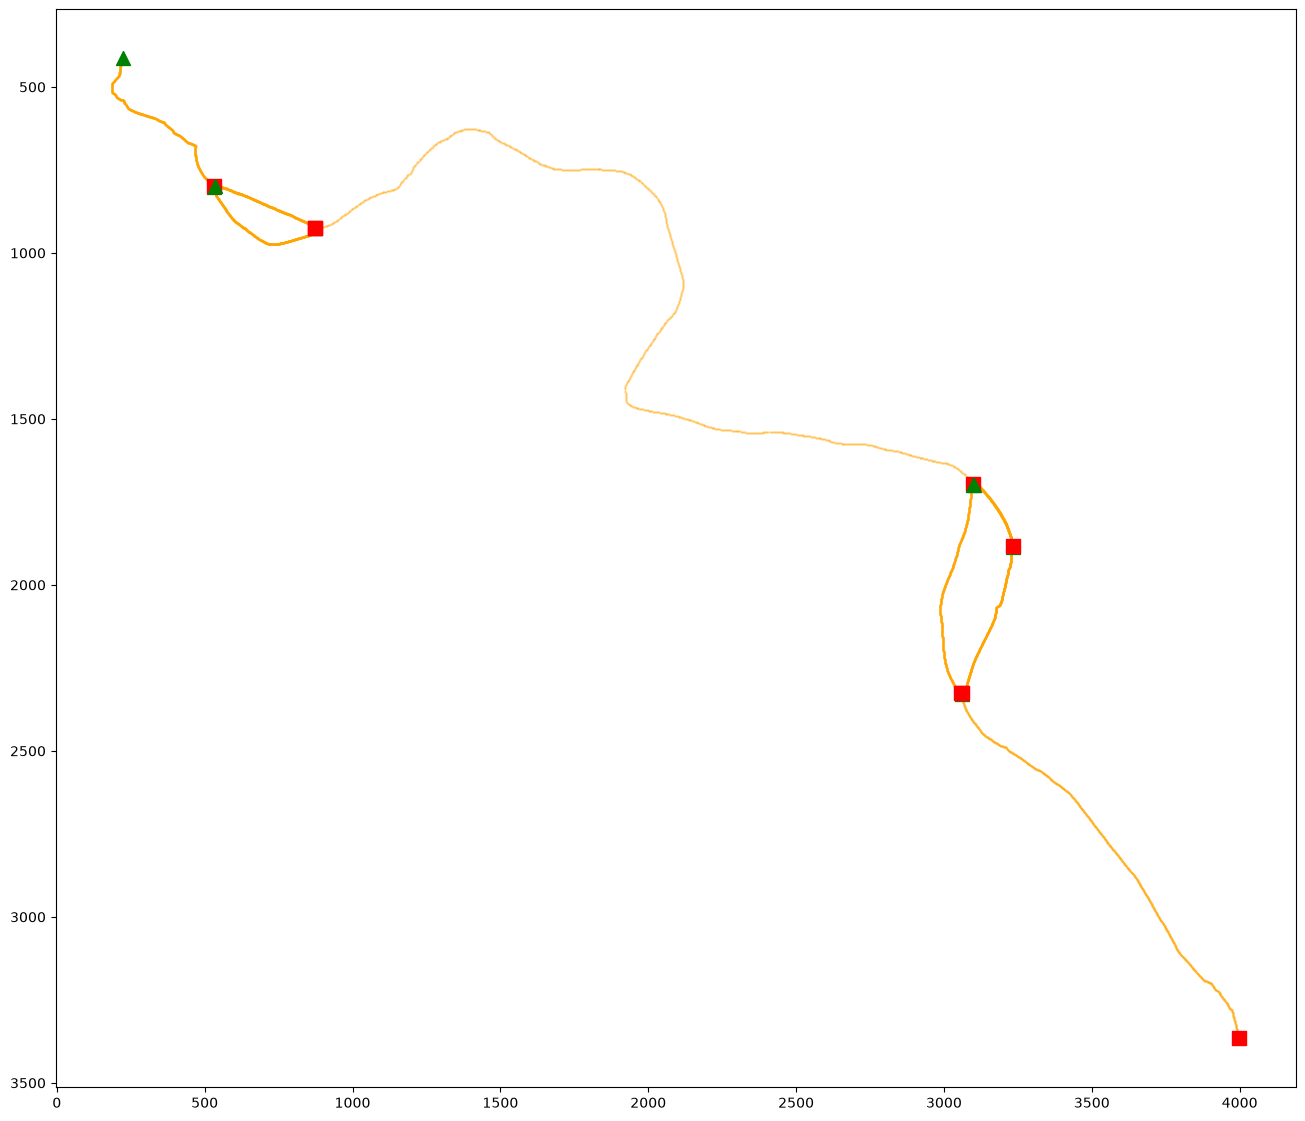

In [3]:
import numpy as np
import networkx as nx
from scipy.interpolate import splprep, splev
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, MultiPoint, Point, LineString, MultiPolygon
from scipy.spatial import cKDTree

def build_spline_network(binary_skeleton, flow_vector=(1, 0), smoothing=5.0):
    """
    针对包含分叉/合并拓扑的骨架，建立按长度参数化的样条方程组
    
    :param binary_skeleton: 连续无断裂的单像素二值骨架图
    :param flow_vector: 宏观河流流向，用于统一各分支的方向，如 (dx, dy)
    :param smoothing: 样条拟合的平滑系数 (s值)
    :return: 包含所有独立样条参数方程的字典
    """
    # 1. 提取点并建立图
    y_idx, x_idx = np.where(binary_skeleton > 0)
    point_set = set(zip(y_idx, x_idx))
    
    G = nx.Graph()
    for y, x in point_set:
        for dy, dx in [(-1,-1), (-1,0), (-1,1), (0,-1), (0,1), (1,-1), (1,0), (1,1)]:
            nb = (y + dy, x + dx)
            if nb in point_set:
                G.add_edge((y, x), nb)
                
    # 2. 寻找交汇点 (度数 >= 3) 并切断图
    junctions = [n for n, d in G.degree() if d >= 3]
    print(f"发现 {len(junctions)} 个交汇点，正在切断图以提取独立线段...")
    junctions_raw = junctions.copy()  # 原始交汇点集合，后续用于聚类合并
    
    # 3. 聚类合并交汇簇（核心修复）
    if len(junctions_raw) > 0:
        junc_list = list(junctions_raw)
        junc_arr = np.array(junc_list)
        tree = cKDTree(junc_arr)
        
        # 距离 ≤ 3 像素的视为同一簇
        pairs = tree.query_pairs(r=3)
        
        # 并查集合并
        parent = {i: i for i in range(len(junc_list))}
        def find(x):
            while parent[x] != x:
                parent[x] = parent[parent[x]]
                x = parent[x]
            return x
        def union(a, b):
            pa, pb = find(a), find(b)
            if pa != pb:
                parent[pb] = pa
        
        for i, j in pairs:
            union(i, j)
        
        # 按簇分组
        clusters = {}
        for i in range(len(junc_list)):
            root = find(i)
            clusters.setdefault(root, []).append(junc_list[i])
        
        # 每簇取几何中心作为唯一交汇点
        junctions = set()
        for pts in clusters.values():
            center = tuple(np.mean(pts, axis=0).astype(int))
            junctions.add(center)
        
        print(f"交汇簇合并: {len(junctions_raw)} → {len(junctions)} 个交汇点")
    else:
        junctions = set()
    
    print(f"发现 {len(junctions)} 个交汇点，正在切断图以提取独立线段...")
    print(f"交汇点坐标: {junctions}")
    
    G_segmented = G.copy()
    G_segmented.remove_nodes_from(junctions_raw)
    
    # 3. 提取所有无分叉的独立线段
    segments = list(nx.connected_components(G_segmented))
    
    spline_network = {}
    flow_vector = np.array(flow_vector)
    
    for seg_id, seg_nodes in enumerate(segments):
        if len(seg_nodes) < 5: 
            continue # 忽略极短的拓扑噪声
            
        # a. 对线段内的点进行空间排序 (重新建子图并寻找两个端点)
        sub_G = G.subgraph(seg_nodes)
        sub_endpoints = [n for n, d in sub_G.degree() if d == 1]
        
        # 如果是环形 (无端点)，暂不处理；正常航道必有两端
        if not sub_endpoints: continue
            
        start_node = sub_endpoints[0]
        # 使用最短路径即可得到严格有序的点序列
        ordered_path = nx.shortest_path(sub_G, source=start_node, target=sub_endpoints[-1])
        
        # b. 流向对齐校验
        path_coords = np.array(ordered_path)
        seg_vector = path_coords[-1] - path_coords[0] # 线段的宏观方向
        if np.dot(seg_vector, flow_vector) < 0:
            path_coords = path_coords[::-1] # 逆流，翻转顺序
            
        # c. 计算累积弧长参数 s
        diffs = np.diff(path_coords, axis=0)
        segment_lengths = np.linalg.norm(diffs, axis=1)
        s_params = np.insert(np.cumsum(segment_lengths), 0, 0)
        
        phys_coords = np.column_stack((path_coords[:, 1]*10, path_coords[:, 0]*10))  # 转换为 (x, y) 坐标
        # d. 三次样条拟合 (B-Spline)
        x_coords = path_coords[:, 1]
        y_coords = path_coords[:, 0]
        
        # splprep 自动处理参数化拟合
        # u 是归一化的参数 [0, 1]，tck 是样条的节点和系数
        tck, u = splprep([x_coords, y_coords], u=s_params, s=smoothing, k=3)
        
        spline_network[f"segment_{seg_id}"] = {
            "tck": tck,                  # 样条方程核心参数
            "length": s_params[-1],      # 该分支的物理总长度
            "start_pt": path_coords[0],  # 锚点
            "end_pt": path_coords[-1],
            "centerline_geom":LineString(phys_coords)
        }
        
    return spline_network

# 使用方法：
# flow_dir = (1, 0.5) # 假设河流整体向右下流
# splines = build_spline_network(continuous_skeleton, flow_vector=flow_dir)




def plot_spline_segment(segment_data, num_points=500):
    """
    基于 tck 参数方程和总长度，绘制单段航道样条曲线
    
    :param segment_data: 字典，包含 'tck', 'length', 'start_pt', 'end_pt'
    :param num_points: 想要在曲线上采样的点数（决定曲线的平滑度）
    """
    tck = segment_data["tck"]
    total_length = segment_data["length"]
    start_pt = segment_data["start_pt"]
    end_pt = segment_data["end_pt"]
    
    # 1. 构建连续的弧长参数 s
    # 在 [0, total_length] 区间内均匀生成 num_points 个参数点
    s_eval = np.linspace(0, total_length, num_points)
    
    # 2. 将参数 s 代入 tck 方程，求出对应的离散 x, y 坐标
    # splev 会自动解析 tck 并返回 (x_array, y_array)
    coords_eval = splev(s_eval, tck)
    x_eval = coords_eval[0]
    y_eval = coords_eval[1]
    
    return coords_eval

# ==========================================
# 调用示例：
# ==========================================


if __name__ == '__main__':
    skeleton = np.load('./skeleton.npy')
    spline_network = build_spline_network(skeleton)
    
    # total_coords = []
    plt.figure(figsize=(16, 14))
    for key in spline_network.keys():

        target_segment = spline_network[key]
        total_length = target_segment["length"]
        start_pt = target_segment["start_pt"]
        end_pt = target_segment["end_pt"]
        
        print(total_length)
        print(start_pt)
        print(end_pt)
        
        cordi = plot_spline_segment(target_segment, num_points=1000)
        # total_coords.append(cordi)
        x_eval = cordi[0]
        y_eval = cordi[1]

        # plt.plot(x_eval, y_eval, color='blue', linewidth=2, label=f"Spline Curve (Len: {total_length:.1f})")
   
        plt.scatter(start_pt[1], start_pt[0], color='green', s=100, marker='^', zorder=5, label='Start Node')
        plt.scatter(end_pt[1], end_pt[0], color='red', s=100, marker='s', zorder=5, label='End Node')
        plt.scatter(x_eval, y_eval, color='orange', s=0.2, alpha=0.5, label='Sampled Points')
        
        
    plt.gca().invert_yaxis() 
    plt.show()


In [20]:
# [2258:2400, 3000:3140]

all_points = [[3000, 2258], [3000, 2400], [3140, 2258], [3140,2400]]
x_min = 495000.0
x_max = 535000.0

y_min = 3385000.0
y_max = 3420000.0

row_num = (int(y_max) - int(y_min)) // 10
col_num = (int(x_max) - int(x_min)) // 10
print(row_num, col_num)

utm_points = []
for point in all_points:
    x = point[0]
    y = point[1]
    new_y = row_num-1-y
    
    x_utm = x_min + x * 10
    y_utm = y_min + new_y * 10
    utm_points.append([x_utm, y_utm])
    print(x_utm, y_utm)


3500 4000
525000.0 3397410.0
525000.0 3395990.0
526400.0 3397410.0
526400.0 3395990.0


dict_keys(['tck', 'length', 'start_pt', 'end_pt', 'centerline_geom'])


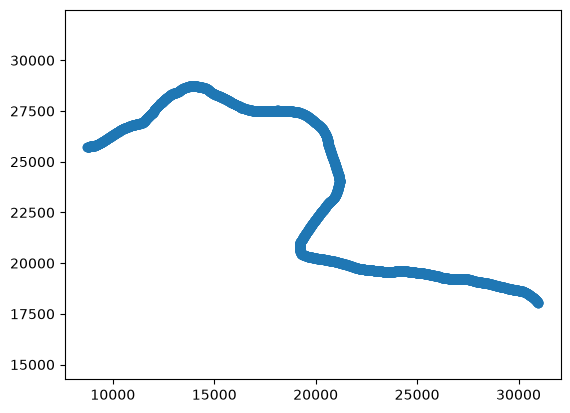

In [ ]:
import pickle
from shapely.geometry import Polygon, MultiPoint, Point, LineString, MultiPolygon

with open('./spline_network.pkl', 'rb') as f:   # 注意 'rb'，二进制读
    spline_network = pickle.load(f)

print(spline_network['segment_0'].keys())

curve = spline_network['segment_0']['centerline_geom']

x, y = curve.xy          # line.xy 返回两个序列
plt.plot(x, y, marker='o')
plt.axis('equal')       # 保证 x/y 比例一致，折线不变形
plt.show()





In [19]:
# [2258:2400, 3000:3140]

all_points = [[3000, 2258], [3000, 2400], [3140, 2258], [3140,2400]]
x_min = 495000.0
x_max = 535000.0

y_min = 3385000.0
y_max = 3420000.0

row_num = (int(y_max) - int(y_min)) // 10
col_num = (int(x_max) - int(x_min)) // 10
print(row_num, col_num)

utm_points = []
for point in all_points:
    x = point[0]
    y = point[1]
    new_y = row_num-1-y
    
    x_utm = x_min + x * 10
    y_utm = y_min + new_y * 10
    utm_points.append([x_utm, y_utm])
    print(x_utm, y_utm)


3500 4000
525000.0 3397410.0
525000.0 3395990.0
526400.0 3397410.0
526400.0 3395990.0
